In [6]:
#%pip install fiona
#%pip install contextily
#%pip install plotly

In [1]:
import pandas as pd  
import matplotlib.pyplot as plt  
import os
import geopandas as gpd  
import numpy as np  
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.io.shapereader import Reader
import matplotlib.patheffects as pe
from IPython.display import Markdown, display
from matplotlib.ticker import FuncFormatter
import seaborn as sns
from matplotlib import gridspec
import matplotlib as mpl
from matplotlib.patches import Patch
from matplotlib.colors import rgb_to_hsv
from matplotlib import colors as mcolors  

In [ ]:
# To preview output, open terminal and paste: 
# quarto preview Manuscript/data_paper_manuscript.ipynb --no-browser

In [ ]:
# To render output to pdf and word, open terminal and paste: 
# quarto render data_paper_manuscript.ipynb --to pdf --to docx

::: {.content-hidden when-format="pdf"}
Title
*Titles must not exceed 110 characters, including whitespaces, and should avoid the use of acronyms (other than very common ones such as DNA, etc), abbreviations, and unnecessary punctuation. Colons and parentheses are not permitted. We recommend only real, technically descriptive words are used to align titles with how users search for information. Do not include dataset brand names in titles, self-constructed acronyms, or words used out of context for the scientific topic, as no user will be searching for them. Capitalise only the first word and any proper nouns and do not include advertising claims not related to the scientific content of the work (e.g. novel, first, AI-ready, open, etc). If unsure, just describe what it is in objective terms.*


Article type = data data descriptor

Title
Author list (does not need a heading)
Abstract
Background & Summary
Methods
Data Records
Data Overview (optional)
Technical Validation
Usage Notes (optional)
Data Availability
Code Availability
References
Author Contributions
Competing Interests
Acknowledgements (optional)
Funding

____________

Abstract
*We recommend the Abstract should not exceed 170 words. It should succinctly describe the data and how it may be used but should not make any claims regarding new scientific findings. We recommend URLs for download, or other details on dataset access, are not included. Please do not use sub-headings to break the Abstract into sections.*

:::

In [14]:
# Count unique aphiaID entries in all_merged.parquet
all_merged = pd.read_parquet("..//All data//all_merged.parquet")
all_stations = pd.read_parquet("..//All data//all_stations.parquet")

records = len(all_merged)
taxa = all_merged['aphiaID'].nunique()
datasets = all_merged['datasetKey'].nunique()
stations = len(all_stations)
start_year = all_merged['year'].min()
end_year = all_merged['year'].max()
gear_percentage = (all_merged['gear'].notna().sum() / records) * 100
biomass_percentage = (all_merged['biomass'].notna().sum() / records) * 100


*Abstract*

In [21]:
display(Markdown(
    f"As the Arctic Ocean undergoes rapid environmental change and is subjected to increasing anthropogenic pressures, there is a growing need for comprehensive baseline data on its biodiversity. Although sampling efforts have been considerable over "
    f"the past decades, the existing biodiversity records are often fragmented and scattered across multiple databases. We present BENTH-MARC, an open pan-Arctic data collection of BENTHos in the Marine ARCtic. BENTH-MARC contains "
    f"{records:,.0f} georeferenced taxon records of {taxa:,.0f} unique taxa from {datasets} datasets and {stations:,.0f} stations, spanning across the entire pan-Arctic realm and integrating data from regional and global biodiversity databases as well as unpublished datasets. "
    f"The records in BENTH-MARC come from over two centuries of sampling, from {start_year:.0f}-{end_year:.0f} and are based on morphological identification. From all records, {gear_percentage:.1f}% have associated information about sampling gear, and {biomass_percentage:.1f}% have linked biomass data. "
    f"By providing harmonized and accessible data, BENTH-MARC can support the assessment of biological consequences of ongoing environmental change, aid in the identification of biodiversity hotspots and evaluation of conservation targets. "
    f"The database can also be used to guide future sampling efforts."
))

As the Arctic Ocean undergoes rapid environmental change and is subjected to increasing anthropogenic pressures, there is a growing need for comprehensive baseline data on its biodiversity. Although sampling efforts have been considerable over the past decades, the existing biodiversity records are often fragmented and scattered across multiple databases. We present BENTH-MARC, an open pan-Arctic data collection of BENTHos in the Marine ARCtic. BENTH-MARC contains 3,614,601 georeferenced taxon records of 10,354 unique taxa from 724 datasets and 163,934 stations, spanning across the entire pan-Arctic realm and integrating data from regional and global biodiversity databases as well as unpublished datasets. The records in BENTH-MARC come from over two centuries of sampling, from 1773-2025 and are based on morphological identification. From all records, 34.4% have associated information about sampling gear, and 5.9% have linked biomass data. By providing harmonized and accessible data, BENTH-MARC can support the assessment of biological consequences of ongoing environmental change, aid in the identification of biodiversity hotspots and evaluation of conservation targets. The database can also be used to guide future sampling efforts.

::: {.content-hidden when-format="pdf"}
*Background: For Data Descriptors, this section should provide an overview of dataset, including the motivation for creating it, as well as outlining the potential reuse value where applicable. Any previous publications that used these data, in whole or in part, should be cited and briefly summarised. Introductions for Articles should provide a similar explanation of why the work was performed and what value you believe it adds. Please note that because Data Descriptors do not present results or analyses there is no formal mandate to cite a given amount of prior art for comparison, however we recommend that at least some other datasets or outputs relevant to the field are cited for readers' general interest. Please do not include subjective claims on novelty, impact, or utility.*
:::

# Background & Summary

The Arctic Ocean is experiencing rapid environmental changes and an increase in anthropogenic pressures [@overland2019; @bidgood2024], which is in part linked to better accessibility as the sea ice withdraws [@pame2025]. The demand on Arctic resources is expected to increase further in the future, with growing interests in among others deep-sea mining and oil and gas extraction in the region [@bidgood2024]. Currently, there are knowledge gaps on how large-scale biodiversity patterns will respond to these rapid environmental changes and elevated anthropogenic pressures [@brandt2023]. Sampling efforts in the Arctic Ocean have been considerable over the past decades [@ramirezllodra2024], and data accessibility has increased due to improved storage options and the growing prevalence of mandatory data publication [@michner20015]. Nevertheless, existing biodiversity records are often insufficient, fragmented, and scattered across multiple databases [@caff2017]. This creates considerable uncertainties, posing challenges for the sustainable management of the Arctic Ocean.

Benthic communities play a vital role in Arctic marine food webs, nutrient recycling, and the carbon cycle [@kedra2015], while also harboring the majority of marine biodiversity [@sirenko2001]. Furthermore, benthic organisms are widely regarded as key indicators of ecosystem health due to the strong coupling between environmental drivers and benthic distribution patterns [@kraan2010; @kraan2015], as well as their comparatively long lifespans. As a result, studies investigating the impacts of environmentally hazardous activities, such as oil and gas extraction or infrastructure development, often focus on benthic communities. Understanding the current baseline of benthic biodiversity is therefore critical — not only for identifying present biodiversity hotspots but also for predicting the future state of the Arctic Ocean and for supporting the sustainable licensing and operation of environmentally hazardous activities. However, sampling zoobenthos in the Arctic Ocean presents significant challenges, including high costs, logistical difficulties, and limited accessibility. These challenges are particularly pronounced in deep-water areas, where research efforts remain scarce. Most studies to date have concentrated on sea ice, surface waters, and the water column, leaving substantial gaps in our understanding of deep benthic environments [@bluhm2011; @ramirezllodra2024].To ensure that future sampling efforts target the areas of greatest need, it is essential to create an overview of the availability, structure, and coverage of existing data and metadata. Additionally, facilitating reuse of already existing data helps maximize the value of each sampling campaign. 

Previous large-scale compilations of Arctic benthic biodiversity include the works of Bluhm et al. [-@bluhm2011] and Ramirez Llodra et al. [-@ramirezllodra2024] on the basins, a taxon compilation by Sirenko et al. [-@sirenko2001] on the Russian Arctic Seas, an inventory of Arctic shelf seas by Piepenburg et al. [-@piepenburg2011] and a pan-Arctic overview of both shelves and basins by Piepenburg et al. [@piepenburg2024]. 

In [20]:
display(Markdown(
    f"In a time of global change and competing land-use interests, large-scale analyses at high taxonomic resolution are key for informing effective science-based decision-making. Such analyses can "
    f"be facilitated and improved by access to harmonized biodiversity and biomass data. Here, we present BENTH-MARC, an open pan-Arctic data collection of BENTHos in the Marine ARCtic. BENTH-MARC "
    f"includes {records:,.0f} morphologically identified zoobenthic records from the Global Biodiversity Information Facility (GBIF), Ocean Biodiversity Information System (OBIS), CRITTERBASE, Observatoire "
    f"Global du Saint-Laurent (OGSL) and unpublished datasets. The records span over the Arctic Large Marine Ecosystems [@pame2013] "
    f"and date back to as early as {start_year:.0f}. The records have been cleaned and harmonized and are now available for download in different formats. By providing harmonized and accessible data, "
    f"BENTH-MARC can support the assessment of biological consequences of ongoing environmental change and can be used to guide future sampling efforts. "
))

In a time of global change and competing land-use interests, large-scale analyses at high taxonomic resolution are key for informing effective science-based decision-making. Such analyses can be facilitated and improved by access to harmonized biodiversity and biomass data. Here, we present BENTH-MARC, an open pan-Arctic data collection of BENTHos in the Marine ARCtic. BENTH-MARC includes 3,614,601 morphologically identified zoobenthic records from the Global Biodiversity Information Facility (GBIF), Ocean Biodiversity Information System (OBIS), CRITTERBASE, Observatoire Global du Saint-Laurent (OGSL) and unpublished datasets. The records span over the Arctic Large Marine Ecosystems [@pame2013] and date back to as early as 1773. The records have been cleaned and harmonized and are now available for download in different formats. By providing harmonized and accessible data, BENTH-MARC can support the assessment of biological consequences of ongoing environmental change and can be used to guide future sampling efforts. 

::: {.content-hidden when-format="pdf"}
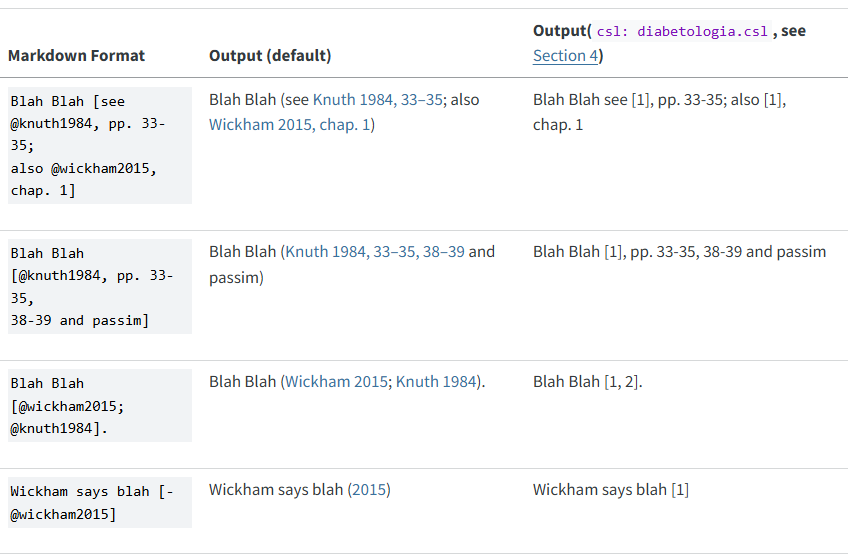
:::

# Methods
## Definition of the study area
The main study area consists of 18 Arctic Large Marine Ecosystems (LMEs), which are regions of ocean space of 200,000 km2 or greater that have unifying qualities in terms of productivity, bathymetry, hydrography and trophically linked populations [@pamend]. The Arctic LMEs were originally developed by the Arctic Council working group Protection of the Arctic Marine Environment (PAME) in 2006 and updated with revised boundaries in 2013 [@pame2013]. Using ecosystem-based units supports the application of an ecosystem approach to management, which has been promoted within the EU Marine Strategy Framework Directive and OSPAR contexts [@pamend]. 

An attempt has been made to access all zoobenthic records from within the Arctic LMEs. @fig-map_stations shows an overview of all sampling stations as well as the extent of the Arctic Large Marine Ecosystems.


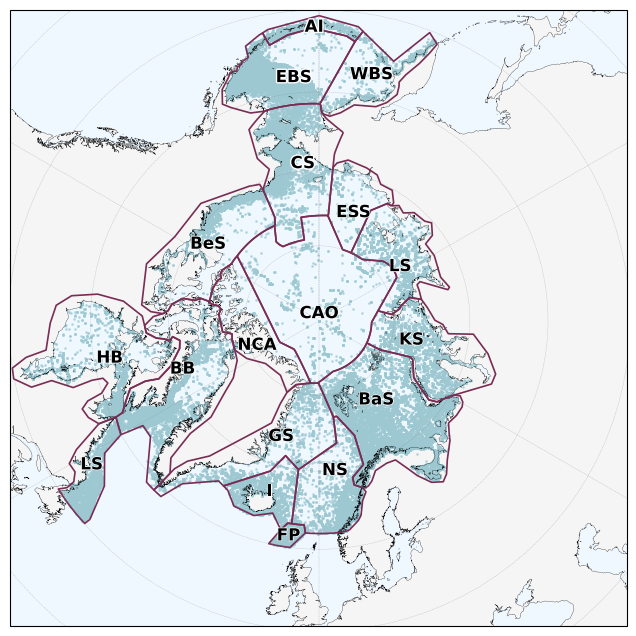

In [5]:
#| fig-pos: "H"
#| label: fig-map_stations
#| fig-cap: "An overview of BENTH-MARC stations. The Arctic Large Marine Ecosystems (purple) define the main study area. The Large Marine Ecosystems are Labrador Sea (LS), Hudson Bay (HB), Baffin Bay (BB), Beaufort Sea (BeS), Chukchi Sea (CS), West Bering Sea (WBS), East Bering Sea (EBS), Aleutian Islands (AI), East Siberian Sea (ESS), Laptev Sea (LS), Kara Sea (KS), Barents Sea (BaS), Norwegian Sea (NS), Iceland (I), Faroe Plateau (FP), Greenland Sea (GS), North Canadian Archipelago (NCA) and Central Arctic Ocean (CAO). "

# Ensure shapefile can be read even if .shx is missing
os.environ['SHAPE_RESTORE_SHX'] = 'YES'

# Load the data from device_water.xlsx
FILEPATH = '..\\All data\\all_stations.parquet'
df_station = pd.read_parquet(FILEPATH)

# Use LatStart and LonStart for coordinates
lat = df_station['decimalLatitudeStart'].copy()
lon = df_station['decimalLongitudeStart'].copy()

# Create coordinates dataframe
coords = pd.DataFrame({
    'lat': pd.to_numeric(lat, errors='coerce'),
    'lon': pd.to_numeric(lon, errors='coerce')
})
coords = coords.dropna()

# Filter to plausible lat/lon ranges
coords = coords[(coords['lat'] >= -90) & (coords['lat'] <= 90) &
                (coords['lon'] >= -180) & (coords['lon'] <= 180)]


# Create the plot with smaller figure size
plt.figure(figsize=(8, 8))
proj = ccrs.NorthPolarStereo()
ax = plt.axes(projection=proj)
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor='whitesmoke')
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')
ax.coastlines(resolution='10m', linewidth=0.2, color='black')
ax.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')

# Add shapefile lines (EPSG:4326, same as stations)
shape_reader = Reader('../LME_boundaries_2014/lme_2013_wgs.shp')
line_feature = cfeature.ShapelyFeature(
    list(shape_reader.geometries()),
    ccrs.PlateCarree(),
    edgecolor='#792D54',
    facecolor='none'
)
ax.add_feature(line_feature, linewidth=1.2)

# Read the shapefile with attributes so we can access names
gdf_lme = gpd.read_file('../LME_boundaries_2014/lme_2013_wgs.shp')

# Ensure coordinates for labeling are in EPSG:4326 (PlateCarree)
gdf_lme_pc = gdf_lme.to_crs(epsg=4326)

# Step 1: Reproject to a projected CRS (e.g., EPSG:3395 for World Mercator)
gdf_lme_projected = gdf_lme.to_crs(epsg=3395)
# Step 2: Calculate centroids in the projected CRS
gdf_lme_projected['centroid'] = gdf_lme_projected.geometry.centroid
# Step 3: Reproject centroids back to the original geographic CRS (EPSG:4326)
gdf_lme_pc['centroid'] = gdf_lme_projected['centroid'].to_crs(epsg=4326)
# Step 4: Extract longitude and latitude for labeling
gdf_lme_pc['lon'] = gdf_lme_pc['centroid'].x  # Extract longitude
gdf_lme_pc['lat'] = gdf_lme_pc['centroid'].y  # Extract latitude


# Step 5: Add labels using the LME field
for _, row in gdf_lme_pc.iterrows():
    if row['LME'] in ['Central Arctic LME', 'Chukchi Sea LME', 'East Bering Sea LME', 'Alutian Islands LME']:
        # Skip these labels in the main loop
        continue
# Handle specific cases for Barents Sea and Beaufort Sea
    if row['LME'] == 'Barents Sea LME':
        short_label = 'BaS'  # Unique abbreviation for Barents Sea
    elif row['LME'] == 'Beaufort Sea LME':
        short_label = 'BeS'  # Unique abbreviation for Beaufort Sea
    else:
        words = row['LME'].split()  # Split the name into words
        short_label = ''.join([word[0] for word in words[:-1]])  # Take the first letter of each word except the last one
    # Add the label to the map
    ax.text(
        row['lon'],
        row['lat'],
        short_label,  # Use the shortened label
        transform=ccrs.PlateCarree(),
        fontsize=12,
        fontweight='bold',  # Make the text bold
        color='black',
        ha='center',
        va='center',
        path_effects=[pe.withStroke(linewidth=1, foreground='white')]
    )

# Step 7: Manual adjustment for problematic labels
for _, row in gdf_lme_pc.iterrows():
    if row['LME'] == 'Central Arctic LME':
        ax.text(
            -179, 89,  # Replace with correct longitude and latitude
            'CAO',
            transform=ccrs.PlateCarree(),
            fontsize=12,
            fontweight='bold',
            color='black',
            ha='center',
            va='center',
            path_effects=[pe.withStroke(linewidth=1, foreground='white')]
        )
    elif row['LME'] == 'Chukchi Sea LME':
        ax.text(
            -174, 69,  # Replace with correct longitude and latitude
            'CS',
            transform=ccrs.PlateCarree(),
            fontsize=12,
            fontweight='bold',
            color='black',
            ha='center',
            va='center',
            path_effects=[pe.withStroke(linewidth=2, foreground='white')]
        )
    elif row['LME'] == 'East Bering Sea LME':
        ax.text(
            -174, 58,  # Replace with correct longitude and latitude
            'EBS',
            transform=ccrs.PlateCarree(),
            fontsize=12,
            fontweight='bold',
            color='black',
            ha='center',
            va='center',
            path_effects=[pe.withStroke(linewidth=2, foreground='white')]
        )
    elif row['LME'] == 'Alutian Islands LME':
        ax.text(
            -179, 52,  # Replace with correct longitude and latitude
            'AI',
            transform=ccrs.PlateCarree(),
            fontsize=12,
            fontweight='bold',
            color='black',
            ha='center',
            va='center',
            path_effects=[pe.withStroke(linewidth=2, foreground='white')]
        )

# Plot the station points
ax.scatter(coords['lon'].values, coords['lat'].values,
           s=1, color='#9DC8D2', alpha=0.6, transform=ccrs.PlateCarree(), label='All stations')


plt.savefig("map_stations.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

## Data sources

BENTH-MARC was created with the intention of including all morphologically identified metazoan invertebrate datasets of meio-, macro- and megabenthos in the Arctic. All georeferenced records belonging to the phyla Annelida, Mollusca, Arthropoda, Echinodermata, Cnidaria, Porifera, Sipuncula, Bryozoa, Chordata, Brachiopoda, Nematoda, Nemertea, Tardigrada, Platyhelminthes, Hemichordata, Kinorhyncha, Priapulida, Loricifera and Phoronida sampled from within the Arctic LMEs (@fig-map_stations) were downloaded from GBIF and OBIS using the R packages rGBIF and robis. The final downloads from GBIF and OBIS were done on xxxx-xx-xx. Data from CRITTERBASE was downloaded through Alfred Wegener's Institute's dedicated web portal on the xxxx-xx-xx. Data from OGSL and unpublished data from Aarhus University were retrieved through personal communication. The records 



## Data cleaning
Downloading all records in the abovementioned phyla from GBIF and OBIS led to an inclusion of a considerable number of pelagic, terrestrial, limnic and extinct taxa. These were at a first stage filtered out using a comprehensive taxonomic filter at the levels of class, order, family and species (see Supplementary material xx). As GBIF and OBIS use different taxonomic backbones, the taxonomic filter was tailored to correspond with the respective data source. The remaining taxa were matched to their functional group as assigned by WoRMS [@worms], which provides information on whether the taxa can be considered benthic or pelagic. The taxa were also matched to their respective environment through WoRMS, which classifies all taxa as marine, brackish, fresh or terrestrial. In 2022, WoRMS had 81% coverage in terms of functional group and 100% coverage in terms of environment for accepted, extant, marine species [@worms2]. Only records belonging to extant marine benthic taxa were kept for further processing. All information about functional groups, environment and status as extant or extinct was accessed through the R package worrms [@worrms]. 

All records belonging to datasets with molecular-, telemetry- or acoustic-based identification or with a main focus on zooplankton, fish or sympagic taxa were removed. Citizen-science datasets without expert-level quality control have been deleted. Records sampled with typically pelagic gear such as plankton net and continuous plankton recorder were excluded and fossil specimens were filtered out. Our filters also targeted the georeferencing quality, removing all records with coordinate uncertainty of >0.01 degrees or >10,000 meters. Records with an unspecified geographical uncertainty were kept. Records with the known default uncertainty values 301, 3036, 999, and 9999 were removed, as they typically have a higher uncertainty than stated by the given value. This was done in accordance with GBIF recommendations [https://data-blog.gbif.org/post/gbif-filtering-guide/]. All records denoting absence were excluded. 

CRITTERBASE, GBIF and OBIS have considerable data overlap. CRITTERBASE was considered the most complete source in terms of metadata and therefore preferred over the other two sources when possible. GBIF has more easily accessible dataset information than OBIS and was therefore given secondary priority. An effort was made to add metadata from OBIS records to GBIF records, whenever there were duplicates between these databases but more metadata had been stored in OBIS. 

    
## Data compilation  
AphiaIDs were retrieved for all taxa in the GBIF subset using the r package worrms [@worrms], whereas the other sources already had AphiaIDs assigned to each taxon. To ensure that all records were updated against the latest taxonomic information available on WoRMS, all records from all sources were stripped of all taxonomic information apart from AphiaID, including scientific name, rank, classification and taxon status. The taxonomic information was then harvested anew from WoRMS using worrms [@worrms], to ensure that all taxonomic information is up-to-date and has been retrieved on the same date for all taxa. 


# Data records
BENTH-MARC can be accessed as one comprehensive .parquet file, 

PANABIO and HAUSGARTEN can be accessed in the global data warehouse CRITTERBASE [@teschke2022]. It is possible to download the data from CRITTERBASE in .csv or .xlsx format. Furthermore, CRITTERBASE allows for a selection of the relevant datasets, region, timespan and gear types. The downloaded data is organized in interlinked sheets, which keeps the number of rows and columns in each sheet to a minimum. This facilitates working with a large number of records and creates an easily accessible overview of the relevant metadata. The metadata includes properties such as date, coordinates, gear type, mesh or sieve size, depth, dataset name, affiliation, contact person and cruise. Taxonomic information is recorded using AphiaIDs from WoRMS, which facilitates scaling from species to higher taxonomic levels.

In [21]:
# PANABIO

In [16]:
df_dataset = pd.read_excel('subsets_water.xlsx', sheet_name='Sheet1')
dataset_count = df_dataset['Project'].nunique()

In [17]:
df_device = pd.read_excel('device_water.xlsx', sheet_name='Sheet1')  
station_count = df_device['DeviceID'].nunique()  

In [18]:
biota_df = pd.read_excel('biota_water.xlsx', sheet_name='Sheet1')
records_count = biota_df['BiotaID'].nunique()

In [19]:
df_biota = pd.read_excel('biota_water.xlsx', sheet_name='Sheet1')  
taxon_count = df_biota['AphiaId (Accepted)'].nunique()  

In [23]:
# HAUSGARTEN

In [41]:
xlsx_path = 'hausgarten.xlsx'

biota_df = pd.read_excel(xlsx_path, sheet_name='Biota')
device_df = pd.read_excel(xlsx_path, sheet_name='Device')
dataset_df = pd.read_excel(xlsx_path, sheet_name='Dataset')

biota_records_hg = biota_df['BiotaID'].nunique()
dataset_hg = dataset_df['Name'].nunique()
device_hg = device_df['DeviceID'].nunique()  
taxa_hg = biota_df['AphiaId (Accepted)'].nunique()  

In [45]:
# Load the Excel file into a DataFrame
biota_phylum_df = pd.read_excel('biota_water_with_phylum.xlsx')
# Normalize the 'Phylum' column by converting to string and stripping whitespace
phylum_series_norm = biota_phylum_df['Phylum'].astype(str).str.strip()
# Calculate total records
total_records = len(biota_phylum_df)
# Calculate the number and percentage of records for 'Annelida'
annelida_records = phylum_series_norm.str.lower().eq('annelida').sum()
percent_annelida = (annelida_records / total_records * 100.0) if total_records > 0 else 0.0
# Calculate the number and percentage of records for 'Arthropoda'
arthropoda_records = phylum_series_norm.str.lower().eq('arthropoda').sum()
percent_arthropoda = (arthropoda_records / total_records * 100.0) if total_records > 0 else 0.0

In [52]:
biota_phylum_df = pd.read_excel('biota_water_with_phylum.xlsx')
phylum_norm = biota_phylum_df['Phylum'].astype(str).str.strip().str.lower()

# Find AphiaId (Accepted) column (robust to minor naming variation)
aphia_acc_col = None
for c in biota_phylum_df.columns:
    name_l = str(c).lower()
    if 'aphia' in name_l and 'accept' in name_l:
        aphia_acc_col = c
        break
if aphia_acc_col is None:
    raise ValueError('Could not find AphiaId (Accepted) column.')

# Coerce IDs to numeric for consistent uniqueness
aphia_norm = pd.to_numeric(biota_phylum_df[aphia_acc_col], errors='coerce')

_norm_df = pd.DataFrame({
    'phylum_norm': phylum_norm,
    'aphia_norm': aphia_norm
}).dropna(subset=['aphia_norm'])

unique_taxa_overall = _norm_df['aphia_norm'].nunique()
unique_taxa_arthropoda = _norm_df.loc[_norm_df['phylum_norm'] == 'arthropoda', 'aphia_norm'].nunique()
unique_taxa_annelida = _norm_df.loc[_norm_df['phylum_norm'] == 'annelida', 'aphia_norm'].nunique()

pct_unique_arthropoda = (unique_taxa_arthropoda / unique_taxa_overall * 100.0) if unique_taxa_overall > 0 else 0.0
pct_unique_annelida = (unique_taxa_annelida / unique_taxa_overall * 100.0) if unique_taxa_overall > 0 else 0.0


# Data overview

In [57]:
from IPython.display import Markdown, display

display(Markdown(
    f"Since the first PANABIO overview was produced on 13th of December 2023 [@piepenburg2024], the compilation has roughly doubled in size. {dataset_count-27-dataset_hg} new datasets have been added to PANABIO, adding up to a new total of "
    f"{dataset_count-dataset_hg} datasets. 17 of these datasets have been previously compiled during Arctic Ocean Diversity (ArcOD) project [@piepenburg2011]. Whereas PANABIO includes a combination of meiobenthic, macrobenthic and megabenthic datasets, " 
    f"HAUSGARTEN mainly includes meiobenthic datasets. PANABIO contains a total of {records_count-biota_records_hg:,} records over {taxon_count:,} unique taxa, while the HAUSGARTEN compilation is smaller and includes {biota_records_hg:,} "
    f"records over {taxa_hg} unique taxa. In this compilation, a station is treated as a sampling event with a unique combination of coordinates, date and gear. With this as a criterium for what makes up a station, PANABIO includes "
    f"{station_count-device_hg:,} stations and HAUSGARTEN includes {device_hg} stations. "
))

Since the first PANABIO overview was produced on 13th of December 2023 [@piepenburg2024], the compilation has roughly doubled in size. 28 new datasets have been added to PANABIO, adding up to a new total of 55 datasets. 17 of these datasets have been previously compiled during Arctic Ocean Diversity (ArcOD) project [@piepenburg2011]. Whereas PANABIO includes a combination of meiobenthic, macrobenthic and megabenthic datasets, HAUSGARTEN mainly includes meiobenthic datasets. PANABIO contains a total of 237,346 records over 4,116 unique taxa, while the HAUSGARTEN compilation is smaller and includes 9,954 records over 198 unique taxa. In this compilation, a station is treated as a sampling event with a unique combination of coordinates, date and gear. With this as a criterium for what makes up a station, PANABIO includes 12,947 stations and HAUSGARTEN includes 43 stations. 

In [161]:
from IPython.display import Markdown, display

display(Markdown(
    f"@fig-top10phyla shows an overview of the top ten phyla in PANABIO and HAUSGARTEN in terms of number of records. The number of records can be compared to the right-hand side of the figure, where the number of unique taxa per "
    f"phylum is displayed. Annelida is by far the phylum with the highest number of records, with a share of {percent_annelida:.0f} % of the total number of records. However, the highest number of unique taxa ({unique_taxa_arthropoda:,}) "
    f"can be found within the phylum Arthropoda, even though it only has {percent_arthropoda:.0f} % of the total number of records. The phylum Bryozoa stands out in terms of having the highest taxa to records ratio. "
))

@fig-top10phyla shows an overview of the top ten phyla in PANABIO and HAUSGARTEN in terms of number of records. The number of records can be compared to the right-hand side of the figure, where the number of unique taxa per phylum is displayed. Annelida is by far the phylum with the highest number of records, with a share of 46 % of the total number of records. However, the highest number of unique taxa (1,288) can be found within the phylum Arthropoda, even though it only has 20 % of the total number of records. The phylum Bryozoa stands out in terms of having the highest taxa to records ratio. 

In [76]:
#--- FIGURE with top 10 phyla by unique taxa and nr of records ---

In [7]:
# Load the parquet file and compute metrics
df_main = pd.read_parquet('..//All data//all_merged.parquet')
df_main.columns = [c.strip() for c in df_main.columns]  # Strip whitespace from column names
phylum_col = 'phylum'
accepted_col = 'aphiaID'
# Ensure the 'Phylum' column exists
if phylum_col not in df_main.columns:
    raise KeyError(f"Column '{phylum_col}' not found in the data. Available columns: {df_main.columns}")
df_main[accepted_col] = pd.to_numeric(df_main[accepted_col], errors='coerce')
records = df_main.groupby(phylum_col, dropna=False).size().reset_index(name='records')
unique_ids = (
    df_main.dropna(subset=[accepted_col])
          .groupby(phylum_col, dropna=False)[accepted_col]
          .nunique()
          .reset_index(name='unique_aphia')
)
metrics = pd.merge(records, unique_ids, on=phylum_col, how='outer').fillna(0)
metrics['records'] = metrics['records'].astype(int)
metrics['unique_aphia'] = metrics['unique_aphia'].astype(int)
# Union selection
top10_records = metrics.sort_values('records', ascending=False).head(10)[phylum_col].tolist()
top10_unique = metrics.sort_values('unique_aphia', ascending=False).head(10)[phylum_col].tolist()
selected_union = list(dict.fromkeys(top10_records + top10_unique))
# Order by records for plotting
df_union = metrics[metrics[phylum_col].isin(selected_union)].copy()
order_union = df_union.sort_values('records', ascending=False)[phylum_col].tolist()

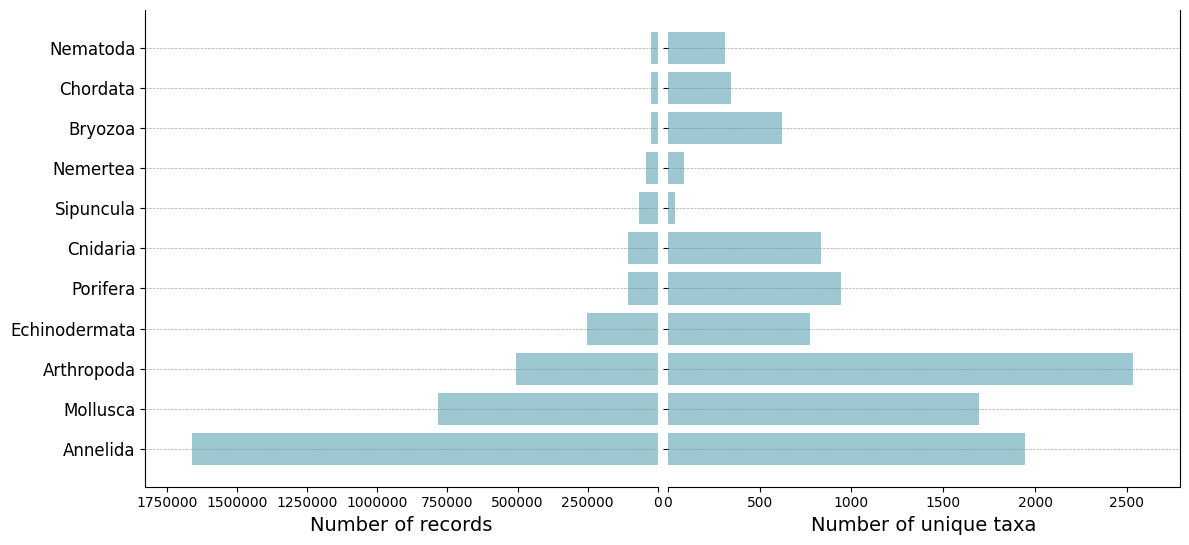

In [10]:
#| label: fig-top10phyla
#| fig-cap: "Top ten phyla in terms of number of records and unique taxa. "
#| fig-pos: "H"

# Cell 2: Plot mirrored barplot (UNION of top-10 by each metric) using variables from Cell 1
# - Separate x-axes; left mirrored; consistent colors; saves PNG


# Define custom colors (replace with your desired colors)
custom_colors = ['#9DC8D2', '#9DC8D2', '#9DC8D2', '#9DC8D2', '#9DC8D2', 
                 '#9DC8D2', '#9DC8D2', '#9DC8D2', '#9DC8D2', '#9DC8D2']
# Map custom colors to phyla
color_map_union = {phy: custom_colors[i % len(custom_colors)] for i, phy in enumerate(order_union)}
phylum_col = 'phylum'
left_df_union = df_union.set_index(phylum_col).loc[order_union].reset_index()
right_df_union = left_df_union.copy()
colors_union = [color_map_union[p] for p in order_union]  # Use custom colors
fig, (ax_left, ax_right) = plt.subplots(
    ncols=2,
    figsize=(12, max(6, int(len(order_union) * 0.6))),
    gridspec_kw={'width_ratios': [1, 1]}
)

# Bars
bars_left = ax_left.barh(left_df_union[phylum_col], -left_df_union['records'], color=colors_union)
bars_right = ax_right.barh(right_df_union[phylum_col], right_df_union['unique_aphia'], color=colors_union)

# Add gridlines to both axes
ax_left.grid(axis='y', color='gray', linestyle='--', linewidth=0.5, alpha=0.7)
ax_right.grid(axis='y', color='gray', linestyle='--', linewidth=0.5, alpha=0.7)

# Axes formatting
ax_left.set_xlabel('Number of records', fontsize=14)
ax_left.set_xlim(-left_df_union['records'].max() * 1.1, 0)
ax_left.spines['right'].set_visible(False)
ax_left.spines['top'].set_visible(False)
ax_left.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: str(int(abs(x)))))

ax_right.set_xlabel('Number of unique taxa', fontsize=14)
ax_right.set_xlim(0, right_df_union['unique_aphia'].max() * 1.1)
ax_right.spines['left'].set_visible(False)
ax_right.spines['top'].set_visible(False)

# Explicit y-ticks and labels
yticks = list(range(len(order_union)))
ax_left.set_yticks(yticks)
ax_left.set_yticklabels(order_union, fontsize=12)
ax_right.set_yticks(yticks)
ax_right.set_yticklabels([])

plt.tight_layout()
plt.subplots_adjust(top=0.9, wspace=0.02)

outfile_labels = 'toptenphyla.png'
plt.savefig(outfile_labels, dpi=220, bbox_inches='tight')
plt.show()

In [ ]:
excel_path = 'biota_water.xlsx'
# Load the Excel file
with pd.ExcelFile(excel_path) as xls:
    sheet_to_use = 'Sheet1' if 'Sheet1' in xls.sheet_names else xls.sheet_names[0]
    df_biota = pd.read_excel(xls, sheet_name=sheet_to_use)
# Compute non-empty counts and percentages for key columns
columns_target = ['Count', 'Abundance', 'PresenceAbsence', 'SumWet']
existing_columns = [c for c in columns_target if c in df_biota.columns]

total_rows = len(df_biota)
nonempty_counts = {}
percentages = {}

for col in existing_columns:
    series = df_biota[col]
    is_entry = series.notna() & (series.astype(str).str.strip() != '')
    count_val = int(is_entry.sum())
    nonempty_counts[col] = count_val
    percentages[col] = (count_val / total_rows) * 100.0 if total_rows > 0 else 0.0

# Standalone percentage variables
abundance_pct = percentages.get('Abundance', None)
presenceabsence_pct = percentages.get('PresenceAbsence', None)
count_pct = percentages.get('Count', None)
sumwet_pct = percentages.get('SumWet', None)

In [194]:
from IPython.display import Markdown, display

display(Markdown(
    f"There are three forms of occurrence metrics in CRITTERBASE: presence, count and abundance. Each record is entered using only one of these metrics. Presence is denoted as a 1, whereas count is the raw count per verbatim sampling area "
    f"and abundance is count per standardized area. At {abundance_pct:.0f} % of the total number of records, abundance is the most common metric. In addition to these sampling metrics, "
    f"{sumwet_pct:.0f} % of the records also have associated biomass data. The maps in @fig-panelmap a) and b) show the biomass coverage and sampling metrics across stations, while the bar plots show the biomass coverage and sampling "
    f"metrics across records. Since stations can have a combination of records with and without biomass coverage as well as a combination of records with different types of sampling metrics, the categories partial (biomass coverage) "
    f"and mixed (sampling metrics) are displayed in the maps. As seen in both maps, the spatial coverage of biomass and abundance data is rather limited, although the number of records in these categories is high. This can partly be "
    f"explained by the prevalence of long-term monitoring programs such as the MAREANO program in Barents Sea and the Norwegian Sea, which typically includes abundance and biomass data (reference). Additionally, MAREANO has has a wide taxonomic focus "
    f"and thus contributes with a high number of records per field campaign. When repeated sampling occurs within such monitoring programs, this leads to an increase in the number of records with certain properties but without "
    f"a corresponding increase in the spatial coverage."
))

There are three forms of occurrence metrics in CRITTERBASE: presence, count and abundance. Each record is entered using only one of these metrics. Presence is denoted as a 1, whereas count is the raw count per verbatim sampling area and abundance is count per standardized area. At 67 % of the total number of records, abundance is the most common metric. In addition to these sampling metrics, 68 % of the records also have associated biomass data. The maps in @fig-panelmap a) and b) show the biomass coverage and sampling metrics across stations, while the bar plots show the biomass coverage and sampling metrics across records. Since stations can have a combination of records with and without biomass coverage as well as a combination of records with different types of sampling metrics, the categories partial (biomass coverage) and mixed (sampling metrics) are displayed in the maps. As seen in both maps, the spatial coverage of biomass and abundance data is rather limited, although the number of records in these categories is high. This can partly be explained by the prevalence of long-term monitoring programs such as the MAREANO program in Barents Sea and the Norwegian Sea, which typically includes abundance and biomass data (reference). Additionally, MAREANO has has a wide taxonomic focus and thus contributes with a high number of records per field campaign. When repeated sampling occurs within such monitoring programs, this leads to an increase in the number of records with certain properties but without a corresponding increase in the spatial coverage.

In [121]:
#| include: false

# Load the Excel file into a DataFrame
df_devices = pd.read_excel('device_water_with_taxa.xlsx')
# Convert the 'unique_aphia_per_device' column to numeric, handle non-numeric values, and drop NaNs
taxa_counts = pd.to_numeric(df_devices['unique_aphia_per_device'], errors='coerce').dropna().astype(int)
# Calculate the total number of records
total_records = len(taxa_counts)
# Define thresholds and calculate percentages below each threshold
thresholds = [5, 10, 20, 50]
percent_below = {}
for t in thresholds:
    percent_below[t] = (int((taxa_counts < t).sum()) / total_records) * 100.0 if total_records > 0 else 0.0
# Expose as individual variables for convenience
pct_lt_5 = percent_below[5]
pct_lt_10 = percent_below[10]
pct_lt_20 = percent_below[20]
pct_lt_50 = percent_below[50]
# Print results
print("Total Records:", total_records)
print("Percentage below 5:", pct_lt_5)
print("Percentage below 10:", pct_lt_10)
print("Percentage below 20:", pct_lt_20)
print("Percentage below 50:", pct_lt_50)

# Find the smallest x where at least 90% of records have fewer than x taxa (strictly < x)
values_sorted = np.sort(taxa_counts.values)
unique_vals = np.unique(values_sorted)

cdf_lt = []
for uv in unique_vals:
    cdf_lt.append((values_sorted < uv).sum() / float(total_records))

# Build small CDF frame (optional use)
cdf_df = pd.DataFrame({'count': unique_vals, 'cdf_lt': cdf_lt})

mask_90 = cdf_df['cdf_lt'] >= 0.9
x_for_90pct_lt = int(cdf_df.loc[mask_90, 'count'].iloc[0]) if mask_90.any() else int(unique_vals.max()) + 1

# Min and max taxa per device
min_taxa = int(taxa_counts.min()) if total_records > 0 else None
max_taxa = int(taxa_counts.max()) if total_records > 0 else None

print(x_for_90pct_lt)
print(min_taxa)
print(max_taxa)

Total Records: 12990
Percentage below 5: 56.666666666666664
Percentage below 10: 66.43571978444957
Percentage below 20: 72.57120862201694
Percentage below 50: 86.30484988452656
60
0
237


In [119]:
from IPython.display import Markdown, display

display(Markdown(
    f"As seen in @fig-panelmap c), most stations have low numbers of records. {pct_lt_10:.0f} % have less than ten records per station, and 90% have less than {x_for_90pct_lt} records per station. The lowest number of records "
    f"per station is one and the highest number is {max_taxa}. In the map, the stations with the highest number of records are drawn on top of stations with lower numbers."
))

As seen in @fig-panelmap c), most stations have low numbers of records. 66 % have less than ten records per station, and 90% have less than 60 records per station. The lowest number of records per station is one and the highest number is 237. In the map, the stations with the highest number of records are drawn on top of stations with lower numbers.

In [79]:
# Figure panel with biomass and sampling metrics

In [ ]:
# Ensure shapefile can be read even if .shx is missing
os.environ['SHAPE_RESTORE_SHX'] = 'YES'
# Load datasets
df_station = pd.read_excel('device_water_with_biomass.xlsx', sheet_name='Sheet1')
df_metric = pd.read_excel('device_water_with_metric.xlsx')
biota_df = pd.read_excel("biota_water.xlsx")
# Prepare data for Plot 1 (Biomass Coverage Map)
df_station['Biomass coverage'] = df_station['Biomass coverage'].fillna('none')
lat = df_station['LatStart'].copy()
lon = df_station['LonStart'].copy()
biomass_coverage = df_station['Biomass coverage'].copy()
coords_biomass = pd.DataFrame({
    'lat': pd.to_numeric(lat, errors='coerce'),
    'lon': pd.to_numeric(lon, errors='coerce'),
    'biomass_coverage': biomass_coverage
}).dropna()
coords_biomass = coords_biomass[(coords_biomass['lat'] >= -90) & (coords_biomass['lat'] <= 90) &
                                (coords_biomass['lon'] >= -180) & (coords_biomass['lon'] <= 180)]
coverage_colors = {'full': '#2C3E50', 'partial': '#BC6D78', 'none': '#9DC8D2'}
drawing_order_biomass = ['none', 'partial', 'full']
# Prepare data for Plot 2 (Sampling Metrics Map)
df_metric['metric_type_norm'] = df_metric['metric_type'].astype(str).str.strip().str.lower()
map_to_cat = {
    'presenceabsence': 'presence',
    'presence_absence': 'presence',
    'presence': 'presence',
    'count': 'count',
    'abundance': 'abundance',
    'mixed': 'mixed'
}
df_metric['metric_category'] = df_metric['metric_type_norm'].map(map_to_cat).fillna('other')
coords_metric = df_metric.rename(columns={'LatStart': 'lat', 'LonStart': 'lon'})[['lat', 'lon', 'metric_category']].dropna()
coords_metric = coords_metric[(coords_metric['lat'] >= -90) & (coords_metric['lat'] <= 90) &
                               (coords_metric['lon'] >= -180) & (coords_metric['lon'] <= 180)]
colors_metric = {'presence': '#9DC8D2', 'count': '#2C3E50', 'abundance': '#BC6D78', 'mixed': '#F1C40F', 'other': 'lightgray'}
drawing_order_metric = ['presence', 'mixed', 'abundance', 'count']
# Prepare data for Plot 3 (Biomass Records Bar Plot)
total_obs = len(biota_df)
with_wet = int(biota_df["SumWet"].notna().sum())
without_wet = int(total_obs - with_wet)
labels_biomass = ["Full", "None"]
counts_biomass = [with_wet, without_wet]
colors_biomass = ["#2C3E50", "#9DC8D2"]
# Prepare data for Plot 4 (Sampling Metrics Bar Plot)
rename_map = {}
for c in biota_df.columns:
    if str(c).strip().lower() == 'presenceabsence':
        rename_map[c] = 'Presence'
biota_df = biota_df.rename(columns=rename_map)
for mcol in ['Count', 'Abundance', 'Presence']:
    if mcol in biota_df.columns:
        biota_df[mcol] = pd.to_numeric(biota_df[mcol], errors='coerce')
n_rows = len(biota_df)
def pct_present(series):
    return float((series.fillna(0).astype(float) > 0).sum()) / float(n_rows) * 100.0 if n_rows > 0 else 0.0
pct_presence = pct_present(biota_df['Presence']) if 'Presence' in biota_df.columns else 0.0
pct_count = pct_present(biota_df['Count']) if 'Count' in biota_df.columns else 0.0
pct_abundance = pct_present(biota_df['Abundance']) if 'Abundance' in biota_df.columns else 0.0
plot_df = pd.DataFrame({
    'Metric': ['Presence', 'Count', 'Abundance'],
    'Percent': [pct_presence, pct_count, pct_abundance]
})
order_metrics = ['Presence', 'Count', 'Abundance']
color_map_metrics = {'Presence': '#9DC8D2', 'Count': '#2C3E50', 'Abundance': '#BC6D78'}

In [ ]:
# Load and process data for the map (Number of taxa per station)
mini_df = pd.read_excel('biota_water_mini.xlsx')
possible_device_cols = ['DeviceID', 'deviceid', 'deviceId', 'device_id']
for col in possible_device_cols:
    if col in mini_df.columns:
        device_col = col
        break
else:
    device_col = mini_df.columns[0]
aphia_col = 'AphiaId (Accepted)' if 'AphiaId (Accepted)' in mini_df.columns else mini_df.columns[1]
counts_per_device = (mini_df.dropna(subset=[device_col])
                              .groupby(device_col)[aphia_col]
                              .nunique()
                              .sort_values(ascending=False))
counts, bin_edges = np.histogram(counts_per_device, bins=100)
df_taxa = pd.read_excel('device_water_with_taxa.xlsx', sheet_name='Sheet1', engine='calamine')
plot_df_taxa = df_taxa.sort_values('unique_aphia_per_device', ascending=True)
# Load and process data for the gear map and bar plot
df_gear = pd.read_excel('device_water_with_gear.xlsx')
biota_df = pd.read_excel("biota_water_with_gear.xlsx")
df_gear['gear_type_norm'] = df_gear['Category'].astype(str).str.strip().str.lower()
map_to_cat = {'trawl': 'trawl', 'grab': 'grab', 'video': 'video'}
df_gear['gear_category'] = df_gear['gear_type_norm'].map(map_to_cat).fillna('other')
coords_gear = df_gear.rename(columns={'LatStart': 'lat', 'LonStart': 'lon'})[['lat', 'lon', 'gear_category']].dropna()
coords_gear = coords_gear[
    (coords_gear['lat'] >= -90) & (coords_gear['lat'] <= 90) &
    (coords_gear['lon'] >= -180) & (coords_gear['lon'] <= 180)
]
colors_gear = {'trawl': '#9DC8D2', 'grab': '#F1C40F', 'video': '#BC6D78', 'other': 'lightgray'}
drawing_order_gear = ['trawl', 'grab', 'video']
# Prepare data for the gear bar plot
biota_df['Category'] = biota_df['Category'].astype(str).str.strip().str.lower().replace({'video': 'image'})
gear_types = ['trawl', 'grab', 'image']
biota_df['gear_category'] = biota_df['Category'].where(biota_df['Category'].isin(gear_types), 'other')
n_rows = len(biota_df)
def pct_present(category):
    return float((biota_df['gear_category'] == category).sum()) / float(n_rows) * 100.0 if n_rows > 0 else 0.0
pct_trawl = pct_present('trawl')
pct_grab = pct_present('grab')
pct_image = pct_present('image')
plot_df_gear = pd.DataFrame({
    'Gear': ['Trawl', 'Grab', 'Image'],
    'Percent': [pct_trawl, pct_grab, pct_image]
})
order_gear = ['Trawl', 'Grab', 'Image']
color_map_gear = {'Trawl': '#9DC8D2', 'Grab': '#F1C40F', 'Image': '#BC6D78'}

In [150]:
#| include: false
df_gear = pd.read_excel('device_water_with_gear.xlsx')

df_gear['Category_norm'] = df_gear['Category'].astype(str).str.strip().str.lower()

total_unique_deviceids = df_gear['DeviceID'].nunique()

device_cat = df_gear[['DeviceID', 'Category_norm']].dropna()
trawl_deviceids = set(device_cat.loc[device_cat['Category_norm'] == 'trawl', 'DeviceID'].unique())
grab_deviceids = set(device_cat.loc[device_cat['Category_norm'] == 'grab', 'DeviceID'].unique())
video_deviceids = set(device_cat.loc[device_cat['Category_norm'] == 'video', 'DeviceID'].unique())

pct_device_trawl = (len(trawl_deviceids) / total_unique_deviceids) * 100.0 if total_unique_deviceids > 0 else 0.0
pct_device_grab = (len(grab_deviceids) / total_unique_deviceids) * 100.0 if total_unique_deviceids > 0 else 0.0
pct_device_video = (len(video_deviceids) / total_unique_deviceids) * 100.0 if total_unique_deviceids > 0 else 0.0

print(pct_device_trawl)
print(pct_device_grab)
print(pct_device_video)

68.3679753656659
31.27790608160123
0.3541185527328714


In [ ]:


display(Markdown(
    f"@fig-panelmap d) shows the main gear categories across stations and records. {pct_device_trawl:.1f} % of the stations have been sampled with various forms of trawls (including all trawls as well as epibenthic sledges, "
    f"dredges and drags), whereas {pct_device_grab:.1f} % of the stations have been sampled using different types of grabs (including among others Van Veen grabs, box corers and multicorers) and only {pct_device_video:.1f} % have "
    f"been sampled using image-based analysis. "
    f"Although grab is less frequently applied at a station level than trawl, the majority of records ({pct_grab:.1f} %) has been collected using grabs. This reflects the higher number of taxa per station that is generally "
    f"associated with sampling infauna. In the map, grab and image stations have a higher drawing order than trawl stations and thus occlude many of the trawl stations that occur in close proximity to the grab and image stations. "
    f"This is particularly true in the well-sampled LMEs Beaufort Sea, Chukchi Sea, Norwegian Sea and Barents Sea. "
))

@fig-panelmap d) shows the main gear categories across stations and records. 68.4 % of the stations have been sampled with various forms of trawls (including all trawls as well as epibenthic sledges, dredges and drags), whereas 31.3 % of the stations have been sampled using different types of grabs (including among others Van Veen grabs, box corers and multicorers) and only 0.4 % have been sampled using image-based analysis. Although grab is less frequently applied at a station level than trawl, the majority of records (71.9 %) has been collected using grabs. This reflects the higher number of taxa per station that is generally associated with sampling infauna. In the map, grab and image stations have a higher drawing order than trawl stations and thus occlude many of the trawl stations that occur in close proximity to the grab and image stations. This is particularly true in the well-sampled LMEs Beaufort Sea, Chukchi Sea, Norwegian Sea and Barents Sea. 

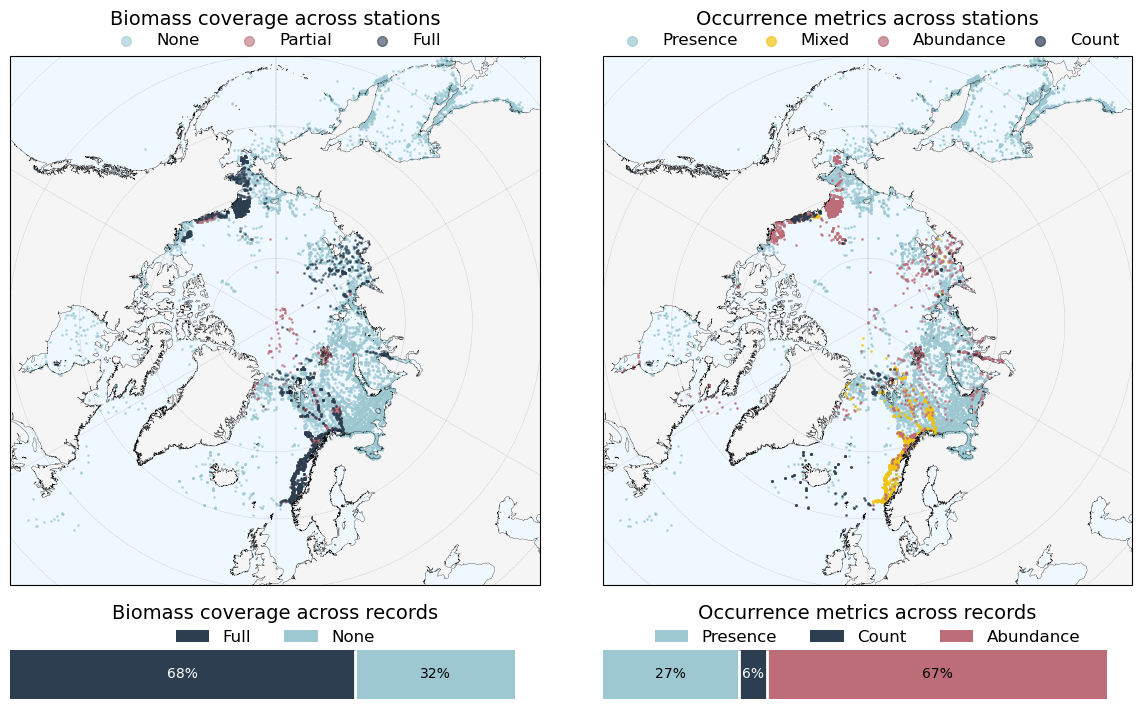

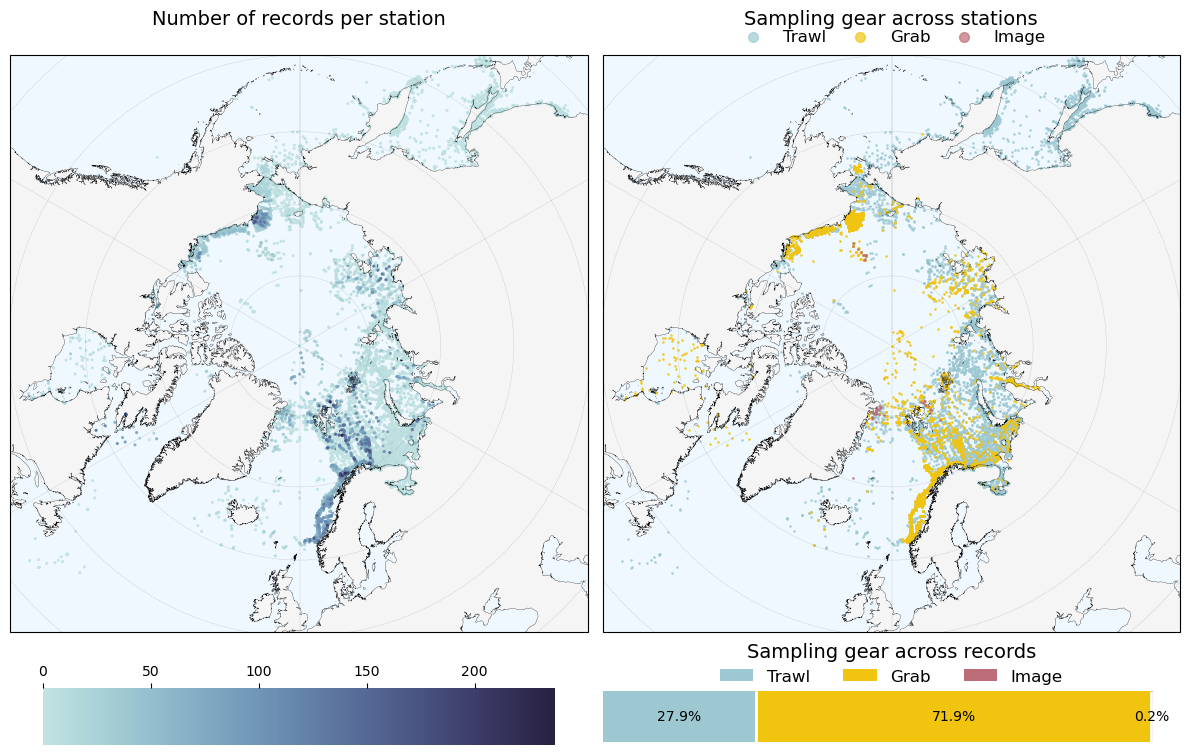

In [ ]:
#| fig-pos: "H"
#| label: fig-panelmap
#| fig-cap: "a) Biomass coverage, b) occurrence metrics, c) number of records and d) sampling gear across stations and records."
#| fig-subcap: []
#| fig-names: false




# Create a figure with a custom grid layout
fig = plt.figure(figsize=(12, 9.5))
gs = gridspec.GridSpec(
    2, 2,  # 2 rows, 2 columns
    width_ratios=[1, 1],  # Adjust the width of each column
    height_ratios=[2, 0.1]  # Adjust the height of each row
)
# Plot 1: Biomass Coverage Map (Top-left, larger height)
ax1 = fig.add_subplot(gs[0, 0], projection=ccrs.NorthPolarStereo())
ax1.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax1.add_feature(cfeature.LAND, facecolor='whitesmoke')
ax1.add_feature(cfeature.OCEAN, facecolor='aliceblue')
ax1.coastlines(resolution='10m', linewidth=0.2, color='black')
ax1.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')
for coverage_type in drawing_order_biomass:
    subset = coords_biomass[coords_biomass['biomass_coverage'] == coverage_type]
    ax1.scatter(subset['lon'].values, subset['lat'].values,
                s=1, color=coverage_colors[coverage_type], alpha=0.6,
                label=coverage_type.capitalize(), transform=ccrs.PlateCarree())
ax1.legend(loc='upper center', bbox_to_anchor=(0.5, 1.07), fontsize=12, ncol=3, markerscale=7, frameon=False)
ax1.set_title('Biomass coverage across stations', pad=22, fontsize=14)

# Plot 2: Sampling Metrics Map (Top-right, larger height)
ax2 = fig.add_subplot(gs[0, 1], projection=ccrs.NorthPolarStereo())
ax2.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax2.add_feature(cfeature.LAND, facecolor='whitesmoke')
ax2.add_feature(cfeature.OCEAN, facecolor='aliceblue')
ax2.coastlines(resolution='10m', linewidth=0.2, color='black')
ax2.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')
for cat in drawing_order_metric:
    sub = coords_metric[coords_metric['metric_category'] == cat]
    ax2.scatter(sub['lon'].values, sub['lat'].values, s=1,
                color=colors_metric.get(cat, 'lightgray'), alpha=0.7,
                label=cat.capitalize(), transform=ccrs.PlateCarree())
ax2.legend(loc='upper center', bbox_to_anchor=(0.5, 1.07), fontsize=12, ncol=4, markerscale=7, frameon=False, columnspacing=1)
ax2.set_title('Occurrence metrics across stations', pad=22, fontsize=14)

# Plot 3: Biomass Records Bar Plot (Bottom-left, smaller height)
ax3 = fig.add_subplot(gs[1, 0])
left_val = 0.0
for i, count in enumerate(counts_biomass):
    bar_color = colors_biomass[i]
    ax3.barh([0], [count], left=left_val, color=bar_color, edgecolor='none', linewidth=0)
    pct = 0 if total_obs == 0 else count / total_obs * 100.0
    x_mid = left_val + count / 2.0
    # Determine text color based on bar color brightness
    rgb = mcolors.to_rgb(bar_color)
    brightness = rgb_to_hsv(rgb)[2]  # Get the value (brightness) from HSV
    text_color = 'white' if brightness < 0.5 else 'black'
    ax3.text(x_mid, 0, f'{pct:.0f}%', ha='center', va='center', fontsize=10, color=text_color)
    left_val += count
# Add small white gaps between segments
gap_left = 0.0
for count in counts_biomass[:-1]:
    gap_left += count
    ax3.vlines(gap_left, -0.4, 0.4, colors='white', linewidth=2)
# Style for Plot 3
ax3.set_xticks([])
ax3.set_yticks([])
ax3.set_title('Biomass coverage across records', pad=20, fontsize=14)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)
ax3.spines['left'].set_visible(False)
ax3.spines['bottom'].set_visible(False)
ax3.grid(False)
# Add legend for Plot 3
legend_handles = [Patch(facecolor=colors_biomass[i], edgecolor='none', label=labels_biomass[i]) for i in range(len(labels_biomass))]
ax3.legend(
    handles=legend_handles,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.6),  # Position the legend below the plot
    ncol=2,  # Number of columns in the legend
    frameon=False,  # Remove the legend box
    fontsize=12,
)
# Plot 4: Sampling Metrics Bar Plot (Bottom-right, smaller height)
ax4 = fig.add_subplot(gs[1, 1])
left_val = 0.0
for m in order_metrics:
    val = float(plot_df.loc[plot_df['Metric'] == m, 'Percent'].values[0]) if m in list(plot_df['Metric']) else 0.0
    bar_color = color_map_metrics[m]
    ax4.barh([0], [val], left=left_val, color=bar_color, edgecolor='none', linewidth=0)
    # Determine text color based on bar color brightness
    rgb = mcolors.to_rgb(bar_color)
    brightness = rgb_to_hsv(rgb)[2]  # Get the value (brightness) from HSV
    text_color = 'white' if brightness < 0.5 else 'black'
    ax4.text(left_val + val / 2, 0, f'{val:.0f}%', ha='center', va='center', fontsize=10, color=text_color)
    left_val += val
# Add small white gaps between segments
gap_left = 0.0
for m in order_metrics[:-1]:
    gap_left += float(plot_df.loc[plot_df['Metric'] == m, 'Percent'].values[0])
    ax4.vlines(gap_left, -0.4, 0.4, colors='white', linewidth=2)
# Style for Plot 4
ax4.set_xticks([])
ax4.set_yticks([])
ax4.set_title('Occurrence metrics across records', pad=20, fontsize=14)
ax4.spines['top'].set_visible(False)
ax4.spines['right'].set_visible(False)
ax4.spines['left'].set_visible(False)
ax4.spines['bottom'].set_visible(False)
ax4.grid(False)
# Add legend for Plot 4
legend_handles = [Patch(facecolor=color_map_metrics[m], edgecolor='none', label=m) for m in order_metrics]
ax4.legend(
    handles=legend_handles,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.6),  # Position the legend below the plot
    ncol=3,  # Number of columns in the legend
    frameon=False,  #Remove the legend box
    fontsize=12,
)
# Adjust layout
plt.tight_layout()
plt.subplots_adjust(hspace=-0.375)
 
plt.savefig('panel_biomass_metrics.png', dpi=300, bbox_inches='tight', facecolor='white')

# ------------------------------ NEXT FIGURE -----------------------------------------


# Create a figure with a custom grid layout
fig = plt.figure(figsize=(12, 10))
gs = gridspec.GridSpec(
    2, 2,  # 2 rows, 2 columns
    width_ratios=[1, 1],  # Adjust the width of each column
    height_ratios=[2, 0.1]  # Adjust the height of each row
)
# Subplot 1: Map with number of taxa per station
proj = ccrs.NorthPolarStereo()
ax1 = fig.add_subplot(gs[0, 0], projection=proj)
ax1.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax1.add_feature(cfeature.LAND, facecolor='whitesmoke')
ax1.add_feature(cfeature.OCEAN, facecolor='aliceblue')
ax1.coastlines(resolution='10m', linewidth=0.2, color='black')
ax1.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')
# Scatter plot for taxa per station
new_cmap = sns.color_palette("ch:start=.2,rot=-.3", as_cmap=True)
sc = ax1.scatter(
    plot_df_taxa['LonStart'], plot_df_taxa['LatStart'],
    c=plot_df_taxa['unique_aphia_per_device'],
    s=5, cmap=new_cmap,
    edgecolors='k', linewidths=0,
    transform=ccrs.PlateCarree(), alpha=0.9
)
ax1.set_title('Number of records per station', pad=22, fontsize=14)

# Subplot 2: Gear map
ax2 = fig.add_subplot(gs[0, 1], projection=ccrs.NorthPolarStereo())
ax2.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax2.add_feature(cfeature.LAND, facecolor='whitesmoke')
ax2.add_feature(cfeature.OCEAN, facecolor='aliceblue')
ax2.coastlines(resolution='10m', linewidth=0.2, color='black')
ax2.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')
# Loop through gear categories and plot them
for cat in drawing_order_gear:
    sub = coords_gear[coords_gear['gear_category'] == cat]
    display_name = 'Image' if cat == 'video' else cat.capitalize()
    ax2.scatter(sub['lon'].values, sub['lat'].values, s=1,
                color=colors_gear.get(cat, 'lightgray'), alpha=0.7,
                label=display_name, transform=ccrs.PlateCarree())
# Add legend
ax2.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, 1.07),
    fontsize=12,
    ncol=4,
    markerscale=7,
    frameon=False,
    columnspacing=1
)
ax2.set_title('Sampling gear across stations', pad=22, fontsize=14)

# Subplot 3: Horizontal colorbar
ax3 = fig.add_subplot(gs[1, 0])
ax3.axis('off')  # Turn off the axis for the colorbar placeholder
# Add horizontal colorbar with increased size and thickness
norm = mpl.colors.Normalize(vmin=plot_df_taxa['unique_aphia_per_device'].min(),
                            vmax=plot_df_taxa['unique_aphia_per_device'].max())
sm = mpl.cm.ScalarMappable(norm=norm, cmap=new_cmap)
sm.set_array([])
cb = fig.colorbar(sm, ax=ax3, orientation='horizontal', fraction=1, pad=0.05, aspect=9)
# Move ticks, labels, and title above the colorbar
cb.ax.xaxis.set_ticks_position('top')  # Move ticks to the top
cb.ax.xaxis.set_label_position('top')  # Move label to the top
cb.set_label('', fontsize=14, labelpad=10)  # Add label above the colorbar
cb.ax.tick_params(labelsize=10)  # Adjust tick label size
# Remove the border around the colorbar
cb.outline.set_visible(False)

# Subplot 4: Gear bar plot
ax4 = fig.add_subplot(gs[1, 1])
left_val = 0.0
for m in order_gear:
    val = float(plot_df_gear.loc[plot_df_gear['Gear'] == m, 'Percent'].values[0])
    bar_color = color_map_gear[m]
    ax4.barh([0], [val], left=left_val, color=bar_color, edgecolor='none', linewidth=0)
    rgb = mpl.colors.to_rgb(bar_color)
    brightness = rgb[2]
    text_color = 'black' if brightness < 0.5 else 'black'
    ax4.text(left_val + val / 2, 0, f'{val:.1f}%', ha='center', va='center', fontsize=10, color=text_color)
    left_val += val
# Add small white gaps between segments
gap_left = 0.0
for m in order_gear[:-1]:  # Exclude the last segment
    gap_left += float(plot_df_gear.loc[plot_df_gear['Gear'] == m, 'Percent'].values[0])
    ax4.vlines(gap_left, -0.4, 0.4, colors='white', linewidth=2)  # Add vertical white line
# Style for Plot 4
ax4.set_xticks([])
ax4.set_yticks([])
ax4.set_title('Sampling gear across records', pad=22, fontsize=14)
ax4.spines['top'].set_visible(False)
ax4.spines['right'].set_visible(False)
ax4.spines['left'].set_visible(False)
ax4.spines['bottom'].set_visible(False)
ax4.grid(False)
# Add legend for Plot 4
legend_handles = [Patch(facecolor=color_map_gear[m], edgecolor='none', label=m) for m in order_gear]
ax4.legend(
    handles=legend_handles,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.6),
    ncol=3,
    frameon=False,
    fontsize=12,
)
# Adjust layout and save the panel
plt.tight_layout()
plt.subplots_adjust(hspace=-0.375)
plt.savefig('panel_biomass_metrics_updated.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

In [ ]:
# Load the DataFrame if not already in memory
df = pd.read_excel('biota_water_with_LME.xlsx', sheet_name='Sheet1')
# Keep rows with a valid LME
df = df.dropna(subset=['LME'])
# Count records per LME
lme_counts = df.groupby('LME').size().sort_values(ascending=False)
# Compute totals
top3_sum = lme_counts.head(3).sum()
total_records = len(df)
percentage_top3 = (top3_sum / total_records) * 100 if total_records > 0 else float('nan')
# Calculate the contribution of the 5 LMEs with the fewest records
bottom5_sum = lme_counts.tail(5).sum()
percentage_bottom5 = (bottom5_sum / total_records) * 100 if total_records > 0 else float('nan')

formatted_percentage_top3 = f"{percentage_top3:.1f}"
formatted_percentage_bottom5 = f"{percentage_bottom5:.1f}"

# Technical validation
The data in PANABIO come with certain qualities that need to be accounted for when applying the data on larger-scale analyses. While @fig-panelmap can help inform the user on the suitable selection of data for a certain scope, there is also an inherent patchiness in the data that the user needs to be aware of. The data are unevenly distributed over regions, habitat types and depths and the sampling focus has shifted over time. Furthermore, the taxonomic resolution of the data varies. These characteristics are described below in the sections Spatial coverage, Temporal coverage and Taxonomic resolution. 

## Spatial coverage


In [208]:
from IPython.display import Markdown, display

display(Markdown(
    f"The spatial distribution of stations across Arctic LMEs can be seen in @fig-map_stations, while @fig-lme shows an overview of the number of records and unique taxa per LME. Sampling effort in terms of number of "
    f"records varies considerably between the LMEs, with {formatted_percentage_top3} % of the total "
    f"number of records having been collected in the three most well-sampled LMEs Barents Sea, Chukchi Sea "
    f"and Norwegian Sea, whereas the five least sampled LMEs contribute with merely {formatted_percentage_bottom5} % of the total number of records. "
    f"Barents Sea is the most well-sampled and taxon-rich LME, whereas Chukchi Sea is the second most sampled LME, but has taxon numbers "
    f"comparable with the considerably less sampled LMEs Beaufort Sea and Laptev Sea. Hudson Bay stands out in terms of having a low number of records but much higher number of unique taxa."
))

The spatial distribution of stations across Arctic LMEs can be seen in @fig-map_stations, while @fig-lme shows an overview of the number of records and unique taxa per LME. Sampling effort in terms of number of records varies considerably between the LMEs, with 79.1 % of the total number of records having been collected in the three most well-sampled LMEs Barents Sea, Chukchi Sea and Norwegian Sea, whereas the five least sampled LMEs contribute with merely 0.1 % of the total number of records. Barents Sea is the most well-sampled and taxon-rich LME, whereas Chukchi Sea is the second most sampled LME, but has taxon numbers comparable with the considerably less sampled LMEs Beaufort Sea and Laptev Sea. Hudson Bay stands out in terms of having a low number of records but much higher number of unique taxa.

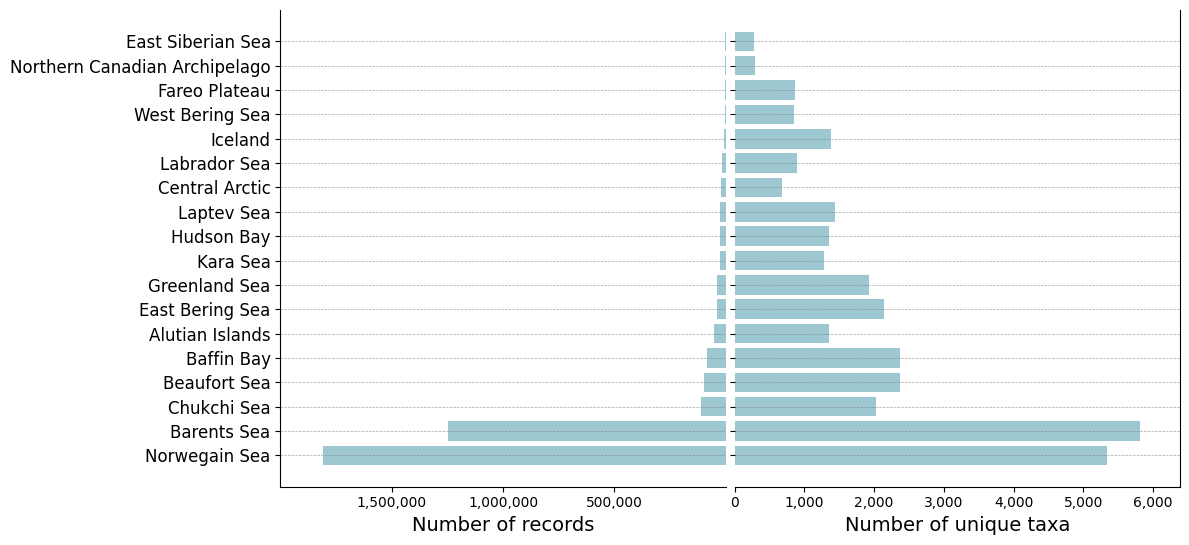

In [34]:
#| label: fig-lme
#| fig-cap: "Number of records and taxa per LME. "

# Load the Excel file
df_main = pd.read_parquet('..//All data//all_merged_geo_LME.parquet')
# Clean column names and handle missing values
df_main.columns = [c.strip() for c in df_main.columns]  # Strip whitespace from column names
lme_col = 'LME'
accepted_col = 'aphiaID'
# Ensure required columns exist
if lme_col not in df_main.columns or accepted_col not in df_main.columns:
    raise KeyError(f"Required column(s) missing: {lme_col} or {accepted_col}")
# Convert 'AphiaId (Accepted)' to numeric and handle missing values in 'LME'
df_main[accepted_col] = pd.to_numeric(df_main[accepted_col], errors='coerce')
df_main[lme_col] = df_main[lme_col].fillna('Outside Arctic LME coverage')
# Remove trailing 'LME' from labels
df_main[lme_col] = df_main[lme_col].astype(str).str.replace(r'\s*LME\s*$', '', regex=True)
# Group by 'LME' to calculate metrics
records = df_main.groupby(lme_col, dropna=False).size().reset_index(name='records')
unique_ids = (
    df_main.dropna(subset=[accepted_col])
          .groupby(lme_col, dropna=False)[accepted_col]
          .nunique()
          .reset_index(name='unique_aphia')
)
# Merge metrics into a single DataFrame
metrics = pd.merge(records, unique_ids, on=lme_col, how='outer').fillna(0)
metrics['records'] = metrics['records'].astype(int)
metrics['unique_aphia'] = metrics['unique_aphia'].astype(int)
# Prepare data for plotting
df_all_lmes = metrics.copy()
order_all_lmes = df_all_lmes.sort_values('records', ascending=False)[lme_col].tolist()
# Define custom colors for the bar plot
custom_colors = ['#9DC8D2'] * len(order_all_lmes)
edge_colors = ['none'] * len(order_all_lmes)  # Default: No edge color
color_map_all = {lme: custom_colors[i % len(custom_colors)] for i, lme in enumerate(order_all_lmes)}
# Update color and edge for "Outside LME coverage"
for i, lme in enumerate(order_all_lmes):
    if lme == 'Outside Arctic LME coverage':
        custom_colors[i] = 'white'  # Set the color to white
        edge_colors[i] = 'grey'    # Set the edge color to grey
        color_map_all[lme] = 'white'
# Create mirrored bar plot
fig, (ax_left, ax_right) = plt.subplots(
    ncols=2, figsize=(12, 6), gridspec_kw={'width_ratios': [1, 1]}
)
# Plot bars
left_df_all = df_all_lmes.set_index(lme_col).loc[order_all_lmes].reset_index()
bars_left = ax_left.barh(left_df_all[lme_col], -left_df_all['records'], color=custom_colors, edgecolor=edge_colors)
bars_right = ax_right.barh(left_df_all[lme_col], left_df_all['unique_aphia'], color=custom_colors, edgecolor=edge_colors)
# Add gridlines to both axes
ax_left.grid(axis='y', color='gray', linestyle='--', linewidth=0.5, alpha=0.7)
ax_right.grid(axis='y', color='gray', linestyle='--', linewidth=0.5, alpha=0.7)
# Format axes
ax_left.set_xlabel('Number of records', fontsize=14)
ax_left.set_xlim(-2000000, 0)
ax_left.spines['right'].set_visible(False)
ax_left.spines['top'].set_visible(False)
ax_left.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{int(abs(x)):,}'))
ax_left.xaxis.set_major_locator(MaxNLocator(nbins=4, prune='both'))
ax_right.set_xlabel('Number of unique taxa', fontsize=14)
ax_right.set_xlim(0, left_df_all['unique_aphia'].max() * 1.1)
ax_right.spines['left'].set_visible(False)
ax_right.spines['top'].set_visible(False)
ax_right.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{int(x):,}'))
# Set y-ticks and labels
yticks = list(range(len(order_all_lmes)))
ax_left.set_yticks(yticks)
ax_left.set_yticklabels(order_all_lmes, fontsize=12)
ax_right.set_yticks(yticks)  # Add y-ticks to align with the left plot
ax_right.set_yticklabels([])  # Remove labels from the right y-axis
# Adjust layout and save the plot
plt.tight_layout()
plt.subplots_adjust(top=0.9, wspace=0.02)
plt.savefig('lme_records_taxa_all.png', dpi=220, bbox_inches='tight')
plt.show()

In [15]:
# Calculate percentages of records on shelves and in abyss

df_geo = pd.read_parquet('..//All data//all_merged_geo.parquet')
# Ensure 'Geo_category' column exists
if 'Geo_category' not in df_geo.columns:
    raise KeyError("The column 'Geo_category' is missing from the dataset.")
# Define shelf categories and flag rows that are on shelves
shelf_levels = {'Shallow shelf', 'Medium shelf', 'Deep shelf'}  # Use a set for efficiency
df_geo['is_shelf'] = df_geo['Geo_category'].isin(shelf_levels)
# Flag abyssal plains
abyss_levels = {'Abyssal plains', 'Abyssal mountains', 'Abyssal hills'}  # Use a set for efficiency
df_geo['is_abyssal'] = df_geo['Geo_category'].isin(abyss_levels)
# Compute counts and percentages for shelves
shelf_count = int(df_geo['is_shelf'].sum())  # Count rows flagged as 'is_shelf'
total_count_geo = int(len(df_geo))  # Total number of rows in the DataFrame
shelf_pct = (shelf_count / total_count_geo) * 100 if total_count_geo > 0 else float('nan')  # Avoid division by zero
# Compute counts and percentages for abyssal plains
abyssal_count = int(df_geo['is_abyssal'].sum())  # Count rows flagged as 'is_abyssal'
abyssal_pct = (abyssal_count / total_count_geo) * 100 if total_count_geo > 0 else float('nan')  # Avoid division by zero

formatted_percentage_shelf_pct = f"{shelf_pct:.1f}"
formatted_percentage_abyssal_pct = f"{abyssal_pct:.1f}"

In [17]:
#| include: false

# Load the dataset
df_geo = pd.read_parquet('..//All data//all_merged_geo.parquet')  # Load if not already in memory
# Define the taxon column
taxon_col = 'acceptedScientificName'
if taxon_col not in df_geo.columns:
    # Find a possible column if the expected one is not present
    possible = [c for c in df_geo.columns if 'ScientificName' in c]
    taxon_col = possible[0] if len(possible) > 0 else df_geo.columns[-1]  # Use the last column as a fallback
# Clean up the 'Geo_category' column
df_geo['Geo_category'] = df_geo['Geo_category'].astype(str).str.strip()
# Group by 'Geo_category' and compute summary statistics
grp = df_geo.groupby('Geo_category', dropna=False)
summary = grp.agg(
    records=('Geo_category', 'size'),  # Count the number of records per Geo_category
    unique_taxa=(taxon_col, pd.Series.nunique)  # Count unique taxa per Geo_category
).reset_index()
# Compute total records and unique taxa
total_records_geo = int(summary['records'].sum())
total_unique_taxa = int(summary['unique_taxa'].sum())
# Compute proportions
summary['prop_records'] = summary['records'] / total_records_geo
summary['prop_unique_taxa'] = summary['unique_taxa'] / total_unique_taxa
# Safe inverses (avoid division by zero)
prop_records_safe = summary['prop_records'].replace(0, np.nan)  # Replace 0 with NaN to avoid division by zero
prop_unique_safe = summary['prop_unique_taxa'].replace(0, np.nan)  # Replace 0 with NaN to avoid division by zero
# Compute ratios
summary['records_to_taxa_ratio'] = prop_records_safe / prop_unique_safe
summary['taxa_to_records_ratio'] = prop_unique_safe / prop_records_safe
# Create a dictionary to store taxa_to_records_ratio for each Geo_category
taxa_to_records_ratios = summary.set_index('Geo_category')['taxa_to_records_ratio'].to_dict()
# Access taxa_to_records_ratio for specific categories
shallow_shelf_ratio = taxa_to_records_ratios.get('Shallow shelf', None)
abyssal_plains_ratio = taxa_to_records_ratios.get('Abyssal plains', None)

Similarly, sampling effort varies considerably over geomorphological features on a pan-Arctic scale. In @fig-geo, the global geomorphological features mapped by @harris2014 have been merged into a coarser set of categories to visualize the distribution of sampling effort in terms of number of records as well as the number of unique taxa per category. As seen in @fig-geo, the shelves are overrepresented in terms of both number of records and number of taxa. 

In [98]:
from IPython.display import Markdown, display

display(Markdown(
    f"The shelves are most easily accessible and the deep, medium and shallow shelf have together received a staggering {formatted_percentage_shelf_pct} % of the overall sampling effort in terms of number of records sampled. "
    f"At the other end of the spectrum, the abyssal plains, mountains and hills have collectively only received {formatted_percentage_abyssal_pct} % of the total sampling effort. "
))

The shelves are most easily accessible and the deep, medium and shallow shelf have together received a staggering 84.7 % of the overall sampling effort in terms of number of records sampled. At the other end of the spectrum, the abyssal plains, mountains and hills have collectively only received 0.6 % of the total sampling effort. 

In [211]:
display(Markdown(
    f"However, as we move to deeper geomorphological categories, the proportional relationship between number of records and number of taxa changes. "
    f"Whereas the shallow shelf has a relative taxa-to-records ratio of {shallow_shelf_ratio:.2f}, "
    f"abyssal plains has a relative taxa-to-records ratio of {abyssal_plains_ratio:.2f}. "
    f"This means that the shallow shelf's share of all unique taxa is roughly {shallow_shelf_ratio*100:.1f} % of its share of all records "
    f"and that it thus contributes fewer unique taxa than what would be expected if taxa scaled one-to-one with records. "
    f"Contrary to this, the abyssal plains have a share of unique taxa that amounts to {abyssal_plains_ratio:.2f} times their share of all records. "
    f"As can be inferred from [@fig-geo], the relative taxa-to-records ratio is generally higher at greater depths. "
))

However, as we move to deeper geomorphological categories, the proportional relationship between number of records and number of taxa changes. Whereas the shallow shelf has a relative taxa-to-records ratio of 0.56, abyssal plains has a relative taxa-to-records ratio of 5.60. This means that the shallow shelf's share of all unique taxa is roughly 55.9 % of its share of all records and that it thus contributes fewer unique taxa than what would be expected if taxa scaled one-to-one with records. Contrary to this, the abyssal plains have a share of unique taxa that amounts to 5.60 times their share of all records. As can be inferred from [@fig-geo], the relative taxa-to-records ratio is generally higher at greater depths. 

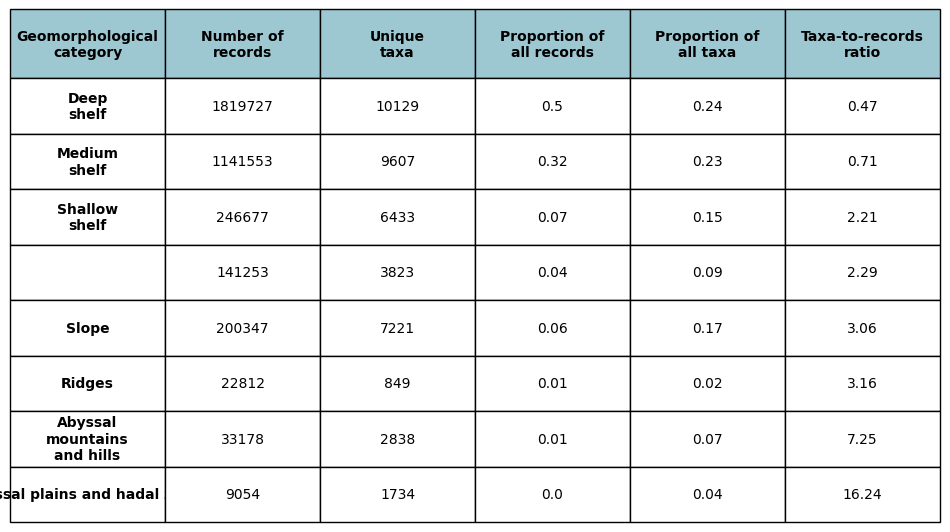

In [18]:
#| include: false
#| fig-pos: "H"
#| label: tbl-geo
#| tbl-cap: The number of records, unique taxa and taxa-to-records ratio of different simplified geomorphological categories, based on @harris2014. 

# Load the dataset
try:
    df_geo
except NameError:
    df_geo = pd.read_parquet('..//All data//all_merged_geo.parquet')  # Load if not already in memory
# Pick the taxa column
taxon_col = 'acceptedScientificName'
if taxon_col not in df_geo.columns:
    # Find potential candidates for the taxon column
    candidates = [c for c in df_geo.columns if 'ScientificName' in c]
    taxon_col = candidates[0] if len(candidates) > 0 else df_geo.columns[-1]
# Clean category text
df_geo['Geo_category'] = df_geo['Geo_category'].astype(str).str.strip().replace('nan', 'Outside geomorphological categories')
# Aggregate data
grp = df_geo.groupby('Geo_category', dropna=False)
summary_table = grp.agg(
    records=('Geo_category', 'size'),
    unique_taxa=(taxon_col, pd.Series.nunique)
).reset_index()
# Compute proportions and ratios
summary_table['prop_records'] = summary_table['records'] / summary_table['records'].sum()
summary_table['prop_unique_taxa'] = summary_table['unique_taxa'] / summary_table['unique_taxa'].sum()
summary_table['taxa_to_records_ratio'] = summary_table['prop_unique_taxa'] / summary_table['prop_records']
# Limit decimals for numeric columns
summary_table['prop_records'] = summary_table['prop_records'].round(2)
summary_table['prop_unique_taxa'] = summary_table['prop_unique_taxa'].round(2)
summary_table['taxa_to_records_ratio'] = summary_table['taxa_to_records_ratio'].round(2)
# Rename columns with row breaks for better formatting
summary_table = summary_table.rename(columns={
    'Geo_category': 'Geomorphological\ncategory',
    'records': 'Number of\nrecords',
    'unique_taxa': 'Unique\ntaxa',
    'prop_records': 'Proportion of\nall records',
    'prop_unique_taxa': 'Proportion of\nall taxa',
    'taxa_to_records_ratio': 'Taxa-to-records\nratio'
})
# Add row breaks to category names for better formatting
summary_table['Geomorphological\ncategory'] = summary_table['Geomorphological\ncategory'].replace({
    'Shallow shelf': 'Shallow\nshelf',
    'Medium shelf': 'Medium\nshelf',
    'Deep shelf': 'Deep\nshelf',
    'Abyssal plains': 'Abyssal\nplains',
    'Abyssal mountains and hills': 'Abyssal\nmountains\nand hills',
    'Outside geomorphological categories': 'Outside\ngeomorphological\ncategories'
})
# Sort the table by proportion of records
summary_table = summary_table.sort_values('Taxa-to-records\nratio', ascending=True)
# Create a styled table as a plot
fig, ax = plt.subplots(figsize=(12, 6))  # Adjust figure size to fit the table
ax.axis('tight')
ax.axis('off')
# Create the table
table = ax.table(
    cellText=summary_table.values,
    colLabels=summary_table.columns,
    cellLoc='center',
    loc='center'
)
# Style the table
table.auto_set_font_size(False)
table.set_fontsize(10)
# Adjust column widths and row heights
for key, cell in table.get_celld().items():
    cell.set_text_props(ha='center', va='center')  # Center-align text
    if key[0] == 0:  # Header row
        cell.set_fontsize(10)
        cell.set_text_props(weight='bold')  # Bold header text
        cell.set_facecolor('#9DC8D2')  # Set header background color
        cell.set_height(0.15)  # Adjust header row height
    else:
        cell.set_height(0.12)  # Adjust row height for data rows
        if key[1] == 0:  # Geomorphological category column
            cell.set_text_props(weight='bold')  # Make category names bold
# Show the table
plt.show()

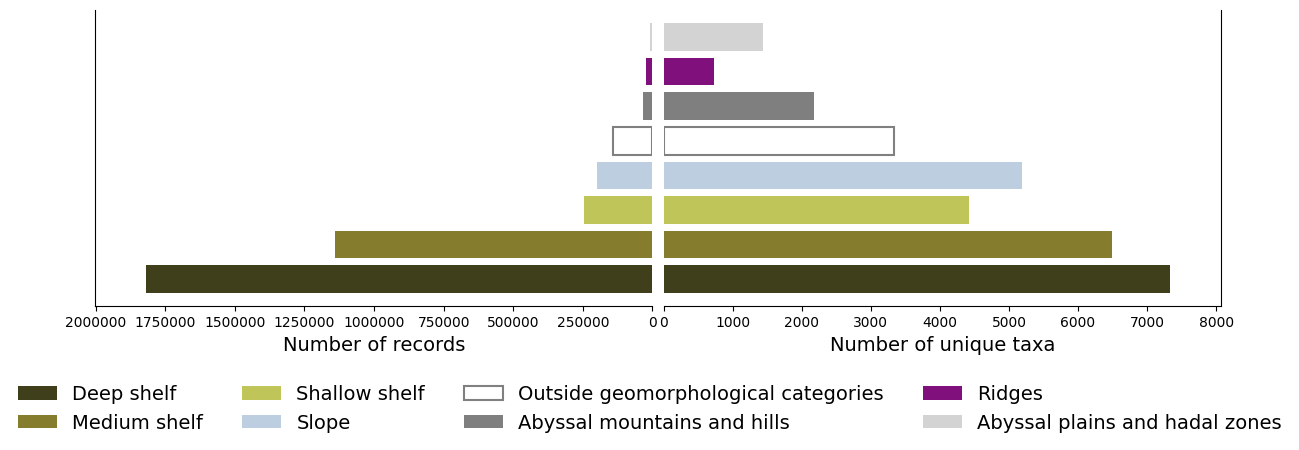

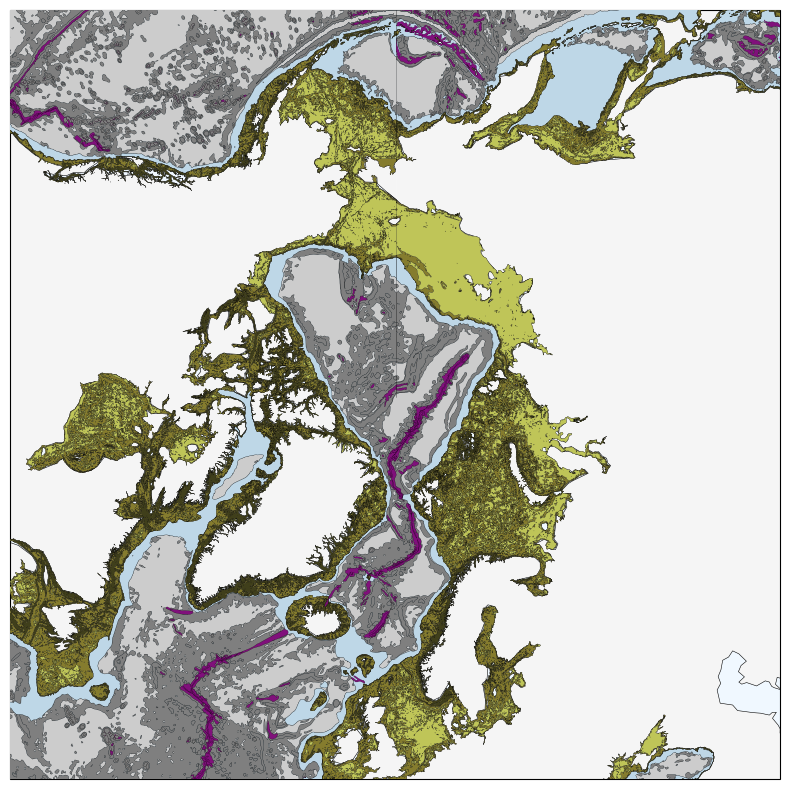

In [ ]:
#| fig-pos: "H"
#| label: fig-geo
#| fig-cap: "An overview of the number of records and taxa per geomorphological category, simplified from @harris2014. "
#| fig-subcap: []

# Load the Excel file
geo_path = '..//All data//all_merged_geo.parquet'
biota_geo_df = pd.read_parquet(geo_path)
# Clean column names and handle missing values
biota_geo_df.columns = [c.strip() for c in biota_geo_df.columns]  # Strip whitespace from column names
geo_col = 'Geo_category'
accepted_col = 'aphiaID'
# Ensure required columns exist
if geo_col not in biota_geo_df.columns or accepted_col not in biota_geo_df.columns:
    raise KeyError(f"Required column(s) missing: {geo_col} or {accepted_col}")
# Convert 'AphiaId (Accepted)' to numeric and handle missing values in 'Geo_category'
biota_geo_df[accepted_col] = pd.to_numeric(biota_geo_df[accepted_col], errors='coerce')
biota_geo_df[geo_col] = biota_geo_df[geo_col].fillna('Outside geomorphological categories')
# Replace empty strings with 'Outside geomorphological categories'
biota_geo_df[geo_col] = biota_geo_df[geo_col].replace('', 'Outside geomorphological categories')
# Strip whitespace and replace any remaining NaN representations
biota_geo_df[geo_col] = biota_geo_df[geo_col].astype(str).str.strip()
biota_geo_df.loc[biota_geo_df[geo_col].isin(['nan', 'None']), geo_col] = 'Outside geomorphological categories'
# Group by 'Geo_category' to calculate metrics
total_records = biota_geo_df.groupby(geo_col, dropna=False).size().reset_index(name='total_records')
unique_taxa = (
    biota_geo_df.dropna(subset=[accepted_col])
                .groupby(geo_col, dropna=False)[accepted_col]
                .nunique()
                .reset_index(name='unique_taxa')
)
# Merge metrics into a single DataFrame
summary_df = pd.merge(total_records, unique_taxa, on=geo_col, how='outer').fillna(0)
summary_df['total_records'] = summary_df['total_records'].astype(int)
summary_df['unique_taxa'] = summary_df['unique_taxa'].astype(int)
# Sort data so that categories with the highest number of records are lowest on the y-axis
summary_df = summary_df.sort_values('total_records', ascending=False)
# Define colors for each category
category_colors = {
    'Abyssal plains': '#C3C3C3',
    'Ridges': '#80107B',
    'Abyssal mountains and hills': '#7F7F7F',
    'Slope': '#BDCEE1',
    'Deep shelf': '#403F1B',
    'Medium shelf': '#857C2E',
    'Shallow shelf': '#BFC558',
    'Outside geomorphological categories': 'white'
}
# Prepare data for plotting
categories = summary_df[geo_col].tolist()
bar_colors = [category_colors.get(cat, 'lightgray') for cat in categories]
# Define edge colors: black border only for "Outside geomorphological coverage"
bar_edge_colors = ['gray' if cat == 'Outside geomorphological categories' else 'none' for cat in categories]
# Create mirrored bar plot
fig, (ax_left, ax_right) = plt.subplots(
    ncols=2, figsize=(12, 4), gridspec_kw={'width_ratios': [1, 1]}
)
# Plot bars
bars_left = ax_left.barh(
    categories, 
    -summary_df['total_records'], 
    color=bar_colors, 
    edgecolor=bar_edge_colors, 
    linewidth=1.5,  # Set border width
    label='Total records'
)
bars_right = ax_right.barh(
    categories, 
    summary_df['unique_taxa'], 
    color=bar_colors, 
    edgecolor=bar_edge_colors, 
    linewidth=1.5,  # Set border width
    label='Unique taxa'
)
# Format axes
ax_left.set_xlabel('Number of records', fontsize=14)
ax_left.set_xlim(-summary_df['total_records'].max() * 1.1, 0)
ax_left.spines['right'].set_visible(False)
ax_left.spines['top'].set_visible(False)
ax_left.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: str(int(abs(x)))))
ax_right.set_xlabel('Number of unique taxa', fontsize=14)
ax_right.set_xlim(0, summary_df['unique_taxa'].max() * 1.1)
ax_right.spines['left'].set_visible(False)
ax_right.spines['top'].set_visible(False)
# Remove y-ticks and labels
ax_left.set_yticks([])
ax_left.set_yticklabels([])
ax_right.set_yticks([])
ax_right.set_yticklabels([])
# Add a legend below the plot
legend_labels = [f"{cat}" for cat in categories]
legend_patches = [
    Patch(
        facecolor=category_colors.get(cat, 'lightgray'), 
        edgecolor='gray' if cat == 'Outside geomorphological categories' else 'none', 
        linewidth=1.5
    ) 
    for cat in categories
]
fig.legend(
    legend_patches, 
    legend_labels, 
    loc='lower center', 
    bbox_to_anchor=(0.5, -0.20), 
    ncol=4, 
    fontsize=14, 
    frameon=False,
    markerscale=3
)
# Adjust layout and save the plot
plt.tight_layout()
plt.subplots_adjust(top=0.9, wspace=0.02)
plt.savefig('geo_records_taxa_mirrored_with_legend.png', dpi=220, bbox_inches='tight')
plt.show()

# ------------------------------------------ Map ------------------------------------------------

# Cell 1 — Imports and config

# Folder containing your shapefiles
geo_dir = '..//Geo'
# List of shapefile filenames to load from ./Geo (add more as needed)
layer_files = [
    'Hadal.shp',
    'Abyss.shp',
    'Slope.shp',
    'Shelf.shp',
    'Abyssal_Classification.shp',
    'Shelf_Classification.shp',
    'Spreading_ridges.shp',
    'Ridges.shp',
    'Rift_valleys.shp',
    'Seamounts.shp'
]

# Cell 2 — Load shapefiles from ./Geo
layers = {}
for fname in layer_files:
    fpath = os.path.join(geo_dir, fname)
    if os.path.exists(fpath):
        gdf_loaded = gpd.read_file(fpath)
        key_name = os.path.splitext(fname)[0]
        layers[key_name] = gdf_loaded

# Cell 3 — Configure class colors (RGBA) and defaults
abyssal_class_field = 'Class'  # Update this if your column name differs
abyssal_class_colors = {
    'Hills': (0.498, 0.498, 0.498, 1.0),  # fixed
    'Mountains': (0.498, 0.498, 0.498, 1.0),  # fixed
    'Plains': (0.8, 0.8, 0.8, 1.0)   # fixed
}
shelf_class_field = 'Class'  # Update this if your column name differs
shelf_class_colors = {
    'high': (0.251, 0.247, 0.106, 1.0),  # Light blue
    'medium': (0.522, 0.486, 0.180, 1.0),  # Green
    'low': (0.749, 0.773, 0.345, 1.0)   # Orange
}
layer_colors_rgba = {
    'Hadal': (0.8, 0.8, 0.8, 1.0),  # Dark blue, previously (0.129, 0.443, 0.710, 1.0)
    'Abyss': (0.420, 0.682, 0.843, 1.0),  # Light blue
    'Ridges': (0.502, 0.063, 0.482, 1.0),  # Purple
    'Slope': (0.745, 0.843, 0.906, 1.0),  # Purple
    'Shelf': (0.933, 0.953, 1.0, 1.0),  # Purple
    'Spreading_ridges': (0.502, 0.063, 0.482, 1.0),  # Purple
    'Rift_valleys': (0.502, 0.063, 0.482, 1.0),  # Purple
    'Seamounts': (0.498, 0.498, 0.498, 1.0)  # Purple
}
default_color = (0.5, 0.5, 0.5, 0.5)  # Gray with transparency

# Simplify geometries for faster plotting
simp_tol_deg = 0.02
simplified_layers = {}
for lname, gdf in layers.items():
    sgdf = gdf.copy()
    sgdf['geometry'] = sgdf.geometry.simplify(simp_tol_deg, preserve_topology=True)
    simplified_layers[lname] = sgdf

# Cell 4 — Plot preview (rasterized)
fig = plt.figure(figsize=(8, 8))
ax = plt.axes(projection=ccrs.NorthPolarStereo())
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor='whitesmoke', zorder=0)
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue', zorder=0)
ax.coastlines(resolution='110m', linewidth=0.4, color='black', zorder=2)
legend_handles = []
# Define zorder for each layer explicitly
layer_zorder = {
    'Hadal': 3,
    'Abyss': 4,
    'Abyssal_Classification': 5,
    'Shelf_Classification': 8,
    'Slope': 7,
    'Shelf': 6,
    'Spreading_ridges': 9,
    'Ridges': 10,
    'Rift_valleys': 11,
    'Seamounts': 12
}
# Plot layers in the specified order with explicit zorder
for fname in layer_files:
    lname = os.path.splitext(fname)[0]  # Get layer name without extension
    if lname in simplified_layers:
        gdf = simplified_layers[lname]
        rgba = layer_colors_rgba.get(lname, default_color)
        geoms = [geom for geom in gdf.geometry if geom is not None]
        if len(geoms) > 0:
            artist = ax.add_geometries(
                geoms,
                crs=ccrs.PlateCarree(),
                facecolor=rgba,
                edgecolor='k',
                linewidth=0.15,
                alpha=rgba[3],
                zorder=layer_zorder[lname]  # Use explicit zorder
            )
            legend_handles.append(Patch(facecolor=rgba, edgecolor='k', label=lname))
# Plot Abyssal_Classification with class-specific colors
if 'Abyssal_Classification' in simplified_layers:
    gdfc = simplified_layers['Abyssal_Classification']
    for cls_name, cls_rgba in abyssal_class_colors.items():
        subset = gdfc[gdfc[abyssal_class_field].astype(str) == cls_name]
        geoms = [geom for geom in subset.geometry if geom is not None]
        if len(geoms) > 0:
            artist = ax.add_geometries(
                geoms,
                crs=ccrs.PlateCarree(),
                facecolor=cls_rgba,
                edgecolor='k',
                linewidth=0.12,
                alpha=cls_rgba[3],
                zorder=layer_zorder['Abyssal_Classification']  # Explicit zorder for Abyssal_Classification
            )
            legend_handles.append(Patch(facecolor=cls_rgba, edgecolor='k', label='Abyssal ' + cls_name))
# Plot Shelf_Classification with class-specific colors
if 'Shelf_Classification' in simplified_layers:
    gdfc = simplified_layers['Shelf_Classification']
    for cls_name, cls_rgba in shelf_class_colors.items():
        subset = gdfc[gdfc[shelf_class_field].astype(str) == cls_name]
        geoms = [geom for geom in subset.geometry if geom is not None]
        if len(geoms) > 0:
            artist = ax.add_geometries(
                geoms,
                crs=ccrs.PlateCarree(),
                facecolor=cls_rgba,
                edgecolor='k',
                linewidth=0.12,
                alpha=cls_rgba[3],
                zorder=layer_zorder['Shelf_Classification']  # Explicit zorder for Shelf_Classification
            )

plt.tight_layout()
out_path = 'geo_map.png'
plt.savefig(out_path, dpi=300)
plt.show()


In [ ]:
#| include: false
# Load the dataset if not already in memory
try:
    df_depth
except NameError:
    df_depth = pd.read_excel('biota_water_depth.xlsx')
# Convert 'bathy' column to numeric and calculate absolute depth in meters
df_depth['bathy'] = pd.to_numeric(df_depth['bathy'], errors='coerce')  # Convert to numeric, coercing errors to NaN
depth_m_abs = df_depth['bathy'].abs()  # Take absolute values (depth is negative for bathymetry)
depth_non_na = depth_m_abs.dropna()  # Drop missing values
# Print the first few rows and the total count of non-missing depths
print(depth_non_na.head())
print(f"Number of non-missing depth values: {len(depth_non_na)}")

0    68.070030
1    66.131844
2    66.131844
3    63.168449
4    63.168449
Name: bathy, dtype: float64
Number of non-missing depth values: 247300


In [126]:
#| include: false
# Ensure the prepared series exists (from the previous cell)
try:
    depth_non_na
    depth_m_abs
except NameError:
    df_depth['bathy'] = pd.to_numeric(df_depth['bathy'], errors='coerce')
    depth_m_abs = df_depth['bathy'].abs()
    depth_non_na = depth_m_abs.dropna()
# Total number of non-missing depth values
n_non_na_depth = int(len(depth_non_na))
# Percent deeper than thresholds (> threshold), over non-missing depths
thresholds = [100, 200, 300, 500]
pct_over = {}  # Dictionary to store percentages for each threshold
for t in thresholds:
    pct_over[t] = (
        float((depth_non_na > t).sum()) / n_non_na_depth * 100
        if n_non_na_depth > 0
        else np.nan
    )
# Extract percentages for specific thresholds
pct_over_100 = pct_over[100]
pct_over_200 = pct_over[200]
pct_over_300 = pct_over[300]
pct_over_500 = pct_over[500]
# Median depth (50th percentile)
median_depth_m = float(depth_non_na.median()) if n_non_na_depth > 0 else np.nan
# Percent in 0–1000 m (0 < depth <= 1000)
count_0_1000 = int(((depth_non_na > 0) & (depth_non_na <= 1000)).sum())
pct_in_0_1000 = (
    float(count_0_1000) / n_non_na_depth * 100 if n_non_na_depth > 0 else np.nan
)
# Bundle metrics into a dictionary for convenience
depth_metrics = {
    'n_non_na_depth': n_non_na_depth,
    'pct_over_100': pct_over_100,
    'pct_over_200': pct_over_200,
    'pct_over_300': pct_over_300,
    'pct_over_500': pct_over_500,
    'median_depth_m': median_depth_m,
    'pct_in_0_1000': pct_in_0_1000,
}
# Print the results
print("Depth Metrics:")
print(depth_metrics)
print(f"Percentage deeper than 100m: {pct_over_100:.2f}%")
print(f"Median depth: {median_depth_m:.2f} meters")

Depth Metrics:
{'n_non_na_depth': 247300, 'pct_over_100': 53.44561261625556, 'pct_over_200': 41.76627577840679, 'pct_over_300': 25.299636069551152, 'pct_over_500': 13.242215932066317, 'median_depth_m': 146.5099945068359, 'pct_in_0_1000': 92.3069146785281}
Percentage deeper than 100m: 53.45%
Median depth: 146.51 meters


In [131]:
from IPython.display import Markdown, display

display(Markdown(
    f"As seen in [@fig-depth], the vast majority of sampling has occurred at shallow depths. " 
    f"50 % of the records have been sampled at a depth of less than {median_depth_m:.0f} meters, and only {pct_over_300:.0f} % have been sampled at a "
    f"depth greater than 300 meters. {pct_in_0_1000:.0f} % of the records have been sampled at the top 1000 meters." 
))

As seen in [@fig-depth], the vast majority of sampling has occurred at shallow depths. 50 % of the records have been sampled at a depth of less than 147 meters, and only 25 % have been sampled at a depth greater than 300 meters. 92 % of the records have been sampled at the top 1000 meters.

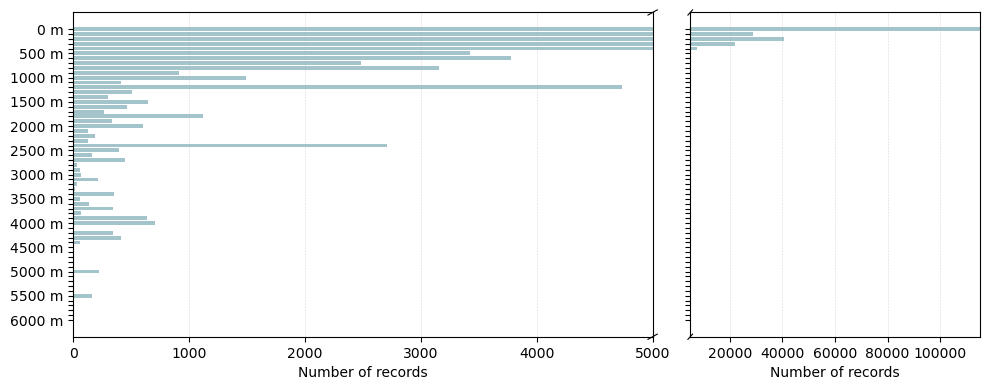

In [40]:
#| label: fig-depth
#| fig-cap: "Number of records over depth."
#| fig-pos: "H"
#| fig-subcap: []

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# Load data
df_depth = pd.read_excel('biota_water_depth.xlsx')
bathy_abs = df_depth['bathy'].dropna().abs()
# Build 100 m bins across full observed range
bin_width = 100
max_depth_full = int(np.ceil(bathy_abs.max() / bin_width) * bin_width)
edges_full = np.arange(0, max_depth_full + bin_width, bin_width)
labels_full = [str(i) + ' to ' + str(i + bin_width) + ' m' for i in range(0, max_depth_full, bin_width)]
binned_full = pd.cut(bathy_abs, bins=edges_full, right=True, include_lowest=True, labels=labels_full)
counts_full = binned_full.value_counts(sort=False).reset_index()
counts_full.columns = ['bin_label', 'records']
counts_full['bin_start'] = counts_full['bin_label'].apply(lambda s: int(str(s).split(' to ')[0]))
counts_full = counts_full.sort_values('bin_start').reset_index(drop=True)
# Filter bins to exclude depths greater than 6000 meters
counts_full = counts_full[counts_full['bin_start'] <= 6000].reset_index(drop=True)
# Create y-tick positions and labels
ytick_positions = np.arange(len(counts_full))
ytick_labels = []
for _, row in counts_full.iterrows():
    start_val = int(str(row['bin_label']).split(' to ')[0].replace(' m', ''))
    if start_val % 500 == 0:
        ytick_labels.append(str(start_val) + ' m')
    else:
        ytick_labels.append('')
# Build the two-panel broken x-axis barplot (left capped at 5000, right shows >5000)
x_break = 5000
right_mask = counts_full['records'] > x_break
fig, (ax1, ax2) = plt.subplots(ncols=2, sharey=True, figsize=(10, 4), gridspec_kw={'width_ratios': [2, 1]})
# Left (0..x_break)
sns.barplot(data=counts_full, y='bin_label', x='records', color='#9DC8D2', orient='h', errorbar=None, ax=ax1)
ax1.set_xlim(0, x_break)
# Right (>x_break)
sns.barplot(data=counts_full[right_mask], y='bin_label', x='records', color='#9DC8D2', orient='h', errorbar=None, ax=ax2)
ax2.set_xlim(x_break, float(counts_full['records'].max()))
# Apply y ticks/labels to both panels
ax1.set_yticks(ytick_positions)
ax1.set_yticklabels(ytick_labels)
ax2.set_yticks(ytick_positions)
ax2.set_yticklabels(ytick_labels)
# Diagonal break markers
d = 0.008
kwargs = dict(transform=ax1.transAxes, color='k', clip_on=False, linewidth=0.8)
ax1.plot((1 - d, 1 + d), (-d, +d), **kwargs)
ax1.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)
kwargs.update(transform=ax2.transAxes)
ax2.plot((-d, +d), (-d, +d), **kwargs)
ax2.plot((-d, +d), (1 - d, 1 + d), **kwargs)
# Style
for ax in (ax1, ax2):
    ax.set_xlabel('Number of records')
    ax.set_ylabel('')
    ax.grid(axis='x', linestyle='--', linewidth=0.4, alpha=0.5, zorder=0)
plt.tight_layout()
plt.show()

In [168]:
#| include: false
import pandas as pd
# Load the dataset if not already in memory
df_dates = pd.read_excel('biota_water_with_datestart.xlsx')
# Parse dates and keep only valid ones
date_parsed = pd.to_datetime(df_dates['DateStart'], errors='coerce')  # Convert to datetime, coercing errors to NaT
valid_dates = date_parsed.dropna()  # Drop invalid dates (NaT)
# Print the first few valid dates and the total count
print("First few valid dates:")
print(valid_dates.head())
print(f"Total number of valid dates: {len(valid_dates)}")

First few valid dates:
0   1980-02-04
1   1927-07-04
2   1927-07-04
3   1927-07-04
4   1927-07-04
Name: DateStart, dtype: datetime64[ns]
Total number of valid dates: 246902


In [169]:
#| include: false
# Ensure valid_dates is defined from the previous cell
try:
    valid_dates
except NameError:
    raise ValueError("The 'valid_dates' series is not defined. Please run the previous cell first.")
# Total number of valid dates
n_valid_dates = int(len(valid_dates))
# Calculate percentage of dates before 2000
before_2000_mask_valid = valid_dates < pd.Timestamp('2000-01-01')
pct_before_2000_valid = (
    (int(before_2000_mask_valid.sum()) / n_valid_dates) * 100
    if n_valid_dates > 0
    else float('nan')
)
# Calculate percentage of dates in the 1800s (1800-01-01 to 1899-12-31)
mask_1800s_valid = (valid_dates >= pd.Timestamp('1800-01-01')) & (valid_dates <= pd.Timestamp('1899-12-31'))
pct_1800s_valid = (
    (int(mask_1800s_valid.sum()) / n_valid_dates) * 100
    if n_valid_dates > 0
    else float('nan')
)
# Print the results
print(f"Percentage of valid dates before 2000: {pct_before_2000_valid:.2f}%")
print(f"Percentage of valid dates in the 1800s: {pct_1800s_valid:.2f}%")

Percentage of valid dates before 2000: 21.42%
Percentage of valid dates in the 1800s: 0.70%


## Temporal coverage

In [182]:
from IPython.display import Markdown, display

display(Markdown(
    f"The data in PANABIO span back all the way to the early 1800s, but only {pct_1800s_valid:.1f} % of the records originate from the 19th century. "
    f"The vast majority of the data are recent, with only {pct_before_2000_valid:.1f} % of the records having been sampled before year 2000 ([@fig-time]). "
    f"Apart from the increasing number of records over time, there also appears to have been a shift in focus from sampling only a few taxonomic groups at a time to "
    f"more community-oriented sampling. @fig-time a) shows the development over time from almost exclusively single-phylum stations to the currently very low "
    f"proportion of stations that only focus on one phylum. This development can be interpreted as a shift in research focus from taxonomy to ecology. "
    f"Together, the limited availability of historic data and the shift in study focus limit the applicability of the data in long-term comparisons."
))

The data in PANABIO span back all the way to the early 1800s, but only 0.7 % of the records originate from the 19th century. The vast majority of the data are recent, with only 21.4 % of the records having been sampled before year 2000 ([@fig-time]). Apart from the increasing number of records over time, there also appears to have been a shift in focus from sampling only a few taxonomic groups at a time to more community-oriented sampling. @fig-time a) shows the development over time from almost exclusively single-phylum stations to the currently very low proportion of stations that only focus on one phylum. This development can be interpreted as a shift in research focus from taxonomy to ecology. Together, the limited availability of historic data and the shift in study focus limit the applicability of the data in long-term comparisons.

@fig-time b) shows the four most common phyla among single-phylum stations. Echinodermata, Arthropoda and Mollusca have received a farily similar focus, whereas Annelida appears to have been the subject of very few targeted studies and other phyla even less. 

*(NB that the selection for CB as of now is biased towards multi-phyla stations over later years, so I will revisit these paragraphs when more data has been added in a more randomised way and we can see whether we actually can see this development.)*

In [105]:
# Load Excel files and compute yearly summaries for:
# - Proportion of Single-phylum devices per year
# - Records per year from biota_water_with_datestart.xlsx

# Load from disk (adjust paths if needed)
df_biota = pd.read_excel('biota_water_with_phylum.xlsx')
df_device = pd.read_excel('device_water.xlsx')
df_biota_dates = pd.read_excel('biota_water_with_datestart.xlsx')

# Classify Single vs Multiple by unique phyla per DeviceID
phylum_counts = df_biota.groupby('DeviceID')['Phylum'].nunique(dropna=True)
class_map = phylum_counts.apply(lambda x: 'Single' if x == 1 else 'Multiple').rename('Phylum_Class').reset_index()

# Merge with device metadata and derive Year from DateStart
merged = pd.merge(df_device, class_map, on='DeviceID', how='inner')
merged['DateStart'] = pd.to_datetime(merged['DateStart'], errors='coerce')
merged = merged.dropna(subset=['DateStart'])
merged['Year'] = merged['DateStart'].dt.year

# Aggregate device counts per year and compute proportion Single
summary_year = (merged.groupby(['Year', 'Phylum_Class'])
                .size()
                .unstack(fill_value=0)
                .reset_index())

# Ensure both columns exist even if absent in some years
if 'Single' not in summary_year.columns:
    summary_year['Single'] = 0
if 'Multiple' not in summary_year.columns:
    summary_year['Multiple'] = 0

summary_year['Total'] = summary_year['Single'] + summary_year['Multiple']
summary_year['Prop_Single'] = summary_year['Single'] / summary_year['Total']

# Compute records per year from biota_water_with_datestart.xlsx
biota_dates = df_biota_dates.copy()
biota_dates['DateStart'] = pd.to_datetime(biota_dates['DateStart'], errors='coerce')
biota_dates = biota_dates.dropna(subset=['DateStart'])
biota_dates['Year'] = biota_dates['DateStart'].dt.year
records_per_year = biota_dates.groupby('Year').size().reset_index(name='RecordCount')

# Merge summaries for aligned plotting
plot_df = pd.merge(summary_year, records_per_year, on='Year', how='left')
plot_df['RecordCount'] = plot_df['RecordCount'].fillna(0).astype(int)
plot_df_sorted = plot_df.sort_values('Year')

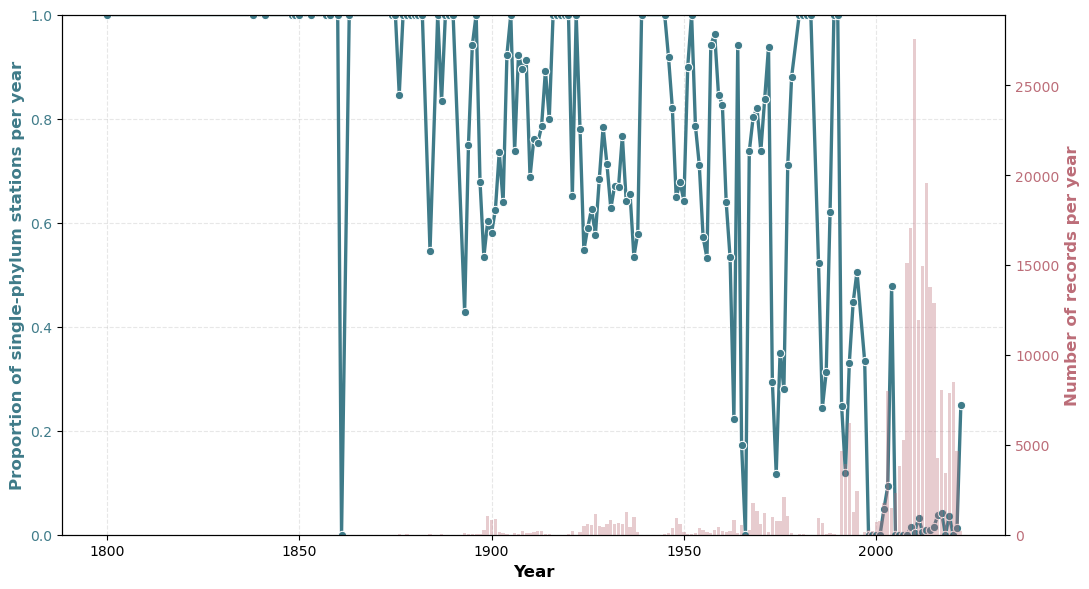

In [88]:
# Plot dual-axis chart with specified colors and draw line on top of bars.
# Save both the figure and the CSV used for plotting.
#| fig-pos: "H"

import matplotlib.pyplot as plt
import seaborn as sns

# Colors per request
color_prop = '#3F7B89'  # proportion single-phylum (line)
color_recs = '#BC6D78'  # biota records per year (bars)

plt.figure(figsize=(11, 6))
ax1 = plt.gca()

# Draw bars first on the secondary axis (so the line can be drawn on top)
ax2 = ax1.twinx()
ax2.bar(plot_df_sorted['Year'], plot_df_sorted['RecordCount'], color=color_recs, alpha=0.35, width=0.85)
ax2.set_ylabel('Number of records per year', color=color_recs, fontsize=12, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color_recs)

# Draw the line on top for visibility
sns.lineplot(data=plot_df_sorted, x='Year', y='Prop_Single', marker='o', color=color_prop, linewidth=2.4, ax=ax1)
ax1.set_ylabel('Proportion of single-phylum stations per year', color=color_prop, fontsize=12, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=color_prop)
ax1.set_ylim(0, 1)
ax1.grid(True, linestyle='--', alpha=0.3)
ax1.set_xlabel('Year', fontsize=12, fontweight='bold')
ax1.set_title('', fontsize=14, fontweight='bold')

# Optional: annotate last points for clarity
last_row = plot_df_sorted.dropna(subset=['Prop_Single']).iloc[-1]

last_row_rec = plot_df_sorted.dropna(subset=['RecordCount']).iloc[-1]

plt.tight_layout()

# Save outputs
fig_path = 'single_phylum_time_with_records_colored.png'
plt.savefig(fig_path, dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

In [174]:
# Build a single stacked bar for device counts per phylum (single-phylum DeviceIDs),
# with segment annotations for counts and percentages.

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_phylum = pd.read_excel('biota_water_with_phylum.xlsx', engine='calamine')

# Identify single-phylum DeviceIDs
phyla_per_device = df_phylum.groupby('DeviceID')['Phylum'].nunique(dropna=True).reset_index(name='n_phyla')
single_device_ids = phyla_per_device.loc[phyla_per_device['n_phyla'] == 1, 'DeviceID']

# Map device -> sole phylum and count devices per phylum
single_df = df_phylum[df_phylum['DeviceID'].isin(single_device_ids)].copy()
sole_phylum_per_device = single_df.groupby('DeviceID')['Phylum'].agg(lambda x: x.dropna().unique()[0] if len(x.dropna().unique())>0 else pd.NA)
phylum_device_counts = sole_phylum_per_device.value_counts().rename_axis('Phylum').reset_index(name='device_count')

# Sort by count descending for legend order and consistent stacking
phylum_device_counts = phylum_device_counts.sort_values('device_count', ascending=False).reset_index(drop=True)

# Compute percentages
total_devices = phylum_device_counts['device_count'].sum()
phylum_device_counts['percent'] = phylum_device_counts['device_count'] / total_devices * 100.0

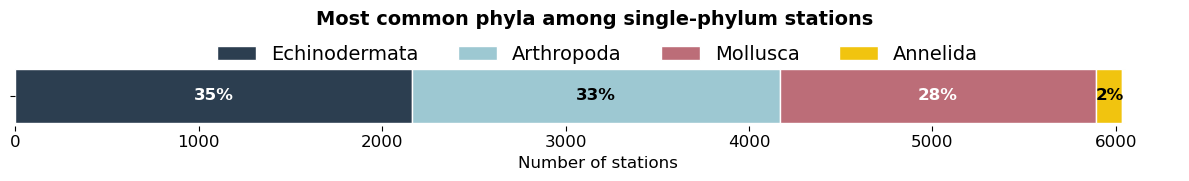

In [196]:
#| label: fig-time
#| fig-cap: "a) Number of records over time and the proportion of single-phylum stations per year, indicating a shift in sampling focus from single-phylum stations to communities. b) shows the phyla that have most commonly been the focus of single-phylum stations."
#| fig-pos: "H"

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Prepare data
labels = phylum_device_counts['Phylum'].tolist()
values = phylum_device_counts['device_count'].tolist()
# Define custom colors for the bars
colors = ['#2C3E50', '#9DC8D2', '#BC6D78', '#F1C40F', '#9DC8D2', '#F1C40F', '#BC6D78', '#2C3E50', '#9DC8D2', '#F1C40F', '#BC6D78', '#2C3E50']
# Ensure the number of colors matches the number of bars
if len(colors) < len(values):
    raise ValueError("Not enough colors provided for the number of bars.")
total_devices = int(np.sum(values))
# Sort data by values in descending order and keep track of the original indices
sorted_data = sorted(zip(labels, values, colors), key=lambda x: x[1], reverse=True)
sorted_labels, sorted_values, sorted_colors = zip(*sorted_data)
# Cumulative left positions for each segment
cum_left = np.cumsum([0] + list(sorted_values[:-1]))
# Plot the bars
plt.figure(figsize=(12, 2.2))
for i, (lab, val, left, color) in enumerate(zip(sorted_labels, sorted_values, cum_left, sorted_colors)):
    plt.barh([0], [val], left=left, color=color, edgecolor='white', height=0.2)
    if i < 4 and val > 0:  # Only show percentages for the top 4 bars
        x_center = left + val / 2.0
        pct = int(round(100.0 * val / total_devices, 1))
        
        # Calculate luminance to determine text color
        r, g, b = [int(color.lstrip('#')[j:j+2], 16) for j in (0, 2, 4)]
        luminance = 0.2126 * r + 0.7152 * g + 0.0722 * b
        txt_color = 'white' if luminance < 128 else 'black'  # White text for dark colors, black for light colors
        
        # Add percentage text
        text_str = f'{pct}%'
        plt.text(x_center, 0, text_str, va='center', ha='center', color=txt_color, 
                 fontsize=12, fontweight='bold')
# Limit the legend to the top 4 bars
top_4_labels = sorted_labels[:4]
top_4_colors = sorted_colors[:4]
plt.legend(top_4_labels, loc='center', bbox_to_anchor=(0.5, 1.2), ncol=4, frameon=False, fontsize=14)
plt.suptitle('Most common phyla among single-phylum stations', fontsize=14, fontweight='bold', y=0.8)
ax = plt.gca()  # Get current axis
for spine in ax.spines.values():
    spine.set_visible(False)  # Hide all spines
# Customize plot
plt.yticks([0], [''])
plt.xlabel('Number of stations', fontsize=12)
plt.xticks(fontsize=12)
# Adjust layout and save the figure
plt.tight_layout()
fig_path = 'single_stacked_bar_top4_legend.png'
plt.savefig(fig_path, dpi=200, bbox_inches='tight')
plt.show()

## Taxonomic resolution

In [198]:
excel_path_rank = 'biota_water_with_rank.xlsx'
with pd.ExcelFile(excel_path_rank) as xls:
    sheet_rank = 'Sheet1' if 'Sheet1' in xls.sheet_names else xls.sheet_names[0]
    df_rank = pd.read_excel(xls, sheet_name=sheet_rank)

rank_series_clean = df_rank['Rank'].astype(str).str.strip()
total_records_rank = len(rank_series_clean)

rank_counts = rank_series_clean.value_counts(dropna=False)
rank_percent = (rank_counts / total_records_rank) * 100.0 if total_records_rank > 0 else rank_counts

rank_summary_df = (
    rank_percent.rename('PercentOfRecords')
    .reset_index()
    .rename(columns={'index': 'Rank'})
    .sort_values('PercentOfRecords', ascending=False)
    .reset_index(drop=True)
)

rank_percent_map = rank_summary_df.set_index('Rank')['PercentOfRecords'].to_dict()

species_pct = rank_percent_map.get('Species')
genus_pct = rank_percent_map.get('Genus')
family_pct = rank_percent_map.get('Family')
order_pct = rank_percent_map.get('Order')
class_pct = rank_percent_map.get('Class')
phylum_pct = rank_percent_map.get('Phylum')

In [201]:
from IPython.display import Markdown, display

display(Markdown(
    f"@fig-tax_resolution shows the taxonomic resolution of the records. The majority of the records ({species_pct:.0f} %) has been identified to species level, followed by genus ({genus_pct:.0f} %) and family level ({family_pct:.0f} %). "
    f"Varying levels of taxonomic resolution can lead to a need for normalizing the records prior to making comparisons. AphiaIDs from WoRMS are included in both PANABIO and HAUSGARTEN, which facilitates scaling from species to higher "
    f"taxonomic levels."
))

@fig-tax_resolution shows the taxonomic resolution of the records. The majority of the records (70 %) has been identified to species level, followed by genus (15 %) and family level (2 %). Varying levels of taxonomic resolution can lead to a need for normalizing the records prior to making comparisons. AphiaIDs from WoRMS are included in both PANABIO and HAUSGARTEN, which facilitates scaling from species to higher taxonomic levels.

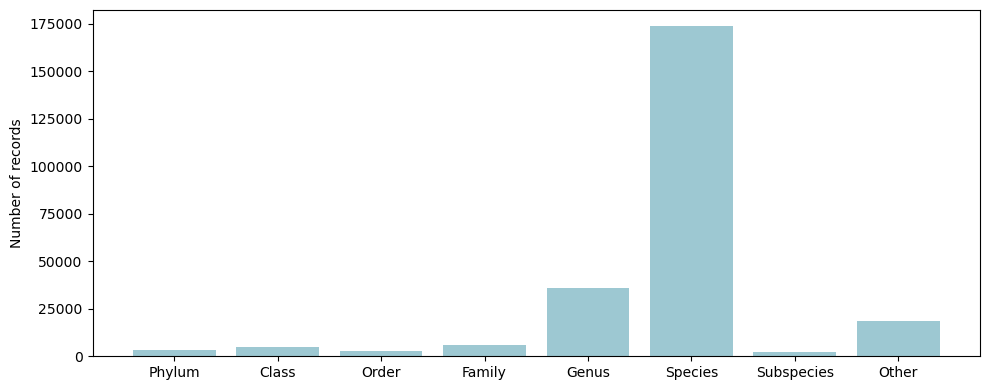

In [197]:
#| label: fig-tax_resolution
#| fig-cap: "Taxonomic resolution of all records. The category *Other* includes intermediate taxonomic levels such as tribe, infraclass and superorder."
#| fig-pos: "H"

import pandas as pd
import matplotlib.pyplot as plt
# Load the data
merged_path = 'biota_water_with_rank.xlsx'
df_merged = pd.read_excel(merged_path, engine='calamine')
# Define the target order
target_order = ['Phylum', 'Class', 'Order', 'Family', 'Genus', 'Species', 'Subspecies']
# Process the Rank column
rank_series = df_merged['Rank'].astype(str).str.strip().str.title()
# Count occurrences of each rank
rank_counts = rank_series.value_counts()
# Separate counts for target_order and "Other"
target_counts = rank_counts.reindex(target_order).fillna(0).astype(int)
other_count = rank_counts[~rank_counts.index.isin(target_order)].sum()
# Create a DataFrame for plotting
rank_counts_df = target_counts.reset_index()
rank_counts_df.columns = ['Rank', 'Count']
# Add the "Other" category using pd.concat
other_df = pd.DataFrame({'Rank': ['Other'], 'Count': [other_count]})
rank_counts_df = pd.concat([rank_counts_df, other_df], ignore_index=True)
# Plot the bar chart
color = '#9DC8D2'
plt.figure(figsize=(10, 4))
plt.bar(rank_counts_df['Rank'], rank_counts_df['Count'], color=color)
plt.ylabel('Number of records', fontsize=10)
plt.xticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()

# Data availability
All data described in this paper are available through the Analyst App at https://critterbase.awi.de/ and can be downloaded by selecting the projects PANABIO and HAUSGARTEN. 

# Code availability
The Python code that was used to generate figures 1-8 can be found in Zenodo/GitHub (add reference).

# References